<a href="https://colab.research.google.com/github/tinhtrau237362/plant-disease-5-crops/blob/main/Chu_de_10_Plant_Disease_5_Crops.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============ CELL 1: SETUP ============
!pip install -q kaggle

import os, random, shutil, re, math, zipfile, subprocess
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU:", gpus)
if not gpus:
    print("⚠️ Chưa bật GPU: Runtime → Change runtime type → T4 GPU (chạy CPU sẽ rất chậm).")

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/plant_disease_results_5crops'
os.makedirs(DRIVE_DIR, exist_ok=True)
CKPT_PATH = '/content/best_model.keras'     # checkpoint tốt nhất (theo val_loss)
print("Thư mục lưu kết quả:", DRIVE_DIR)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Thư mục lưu kết quả: /content/drive/MyDrive/plant_disease_results_5crops


In [ ]:
# ============ CELL 2: TẢI DỮ LIỆU (PlantVillage + Lúa + Xoài + Ớt tùy chọn) ============
from pathlib import Path
from google.colab import files

DATA_ROOT = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
EXTRA_ZIP_DIR = '/content/drive/MyDrive/datasets'    # đặt rice.zip / mango.zip / chili.zip ở đây nếu muốn dùng file có sẵn

SOURCES = {
    'pv':    {'slug': 'abdallahalidev/plantvillage-dataset',     'dir': f'{DATA_ROOT}/plantvillage', 'note': 'Cà chua, Bắp, Ớt chuông'},
    'rice':  {'slug': 'anshulm257/rice-disease-dataset',         'dir': f'{DATA_ROOT}/rice',         'note': 'Lúa'},
    'mango': {'slug': 'aryashah2k/mango-leaf-disease-dataset',   'dir': f'{DATA_ROOT}/mango',         'note': 'Xoài'},
    'chili': {'slug': None,                                      'dir': f'{DATA_ROOT}/chili',         'note': 'Ớt cay (tùy chọn, tải thủ công)'},
}


def count_images(d):
    n = 0
    for _, _, fn in os.walk(d):
        n += sum(f.lower().endswith(IMG_EXTS) for f in fn)
    return n


def find_pv_color():
    for p in Path(DATA_ROOT).rglob('color'):
        if p.is_dir() and (p / 'Tomato___healthy').exists():
            return str(p)
    return None


def have(name):
    return find_pv_color() is not None if name == 'pv' else count_images(SOURCES[name]['dir']) > 0


_kaggle_ready = False
def setup_kaggle():
    global _kaggle_ready
    if _kaggle_ready:
        return
    kj = '/content/drive/MyDrive/kaggle.json'
    if not os.path.exists(kj):
        print("Hãy upload file kaggle.json của bạn:")
        up = files.upload()
        if not up:
            raise RuntimeError("Chưa upload kaggle.json nên không tải được dữ liệu.")
        kj = '/content/kaggle.json'
        with open(kj, 'wb') as f:
            f.write(up[next(iter(up))])             # nhận bất kể tên file (vd: "kaggle (1).json")
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.copy(kj, '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    _kaggle_ready = True


def fetch_source(name):
    cfg = SOURCES[name]
    if have(name):
        print(f"[{name}] đã có sẵn, bỏ qua bước tải.")
        return True
    os.makedirs(cfg['dir'], exist_ok=True)
    z = os.path.join(EXTRA_ZIP_DIR, f'{name}.zip')           # ưu tiên file zip bạn tự đặt trên Drive
    if os.path.exists(z):
        print(f"[{name}] giải nén từ {z} ...")
        with zipfile.ZipFile(z) as zf:
            zf.extractall(cfg['dir'])
        return have(name)
    if cfg['slug']:
        setup_kaggle()
        print(f"[{name}] đang tải {cfg['slug']} ({cfg['note']}) ...")
        r = subprocess.run(['kaggle', 'datasets', 'download', '-d', cfg['slug'], '-p', cfg['dir'], '--unzip'],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(f"❌ [{name}] tải thất bại. Chi tiết:\n{r.stderr[-800:]}")
            print(f"   Cách khác: tải thủ công, zip lại, đặt tên '{name}.zip' vào {EXTRA_ZIP_DIR} rồi chạy lại cell này.")
            return False
        return have(name)
    print(f"[{name}] không có nguồn tự động ({cfg['note']}). Bỏ qua — nếu muốn dùng, đặt '{name}.zip' vào {EXTRA_ZIP_DIR}.")
    return False


OK = {name: fetch_source(name) for name in SOURCES}

PV_ROOT = find_pv_color()
assert PV_ROOT is not None, "Không tìm thấy PlantVillage (thư mục 'color' chứa Tomato___healthy)."
ROOTS = {'pv': PV_ROOT, 'rice': SOURCES['rice']['dir'], 'mango': SOURCES['mango']['dir'], 'chili': SOURCES['chili']['dir']}

print("\n=== TÌNH TRẠNG NGUỒN DỮ LIỆU ===")
for name in SOURCES:
    n = count_images(ROOTS[name]) if name != 'pv' else count_images(PV_ROOT)
    print(f"  {name:6s} {'✅' if OK[name] else '—'}  {n:6d} ảnh  | {SOURCES[name]['note']}")

Hãy upload file kaggle.json của bạn:


Saving kaggle.json to kaggle.json
[pv] đang tải abdallahalidev/plantvillage-dataset (Cà chua, Bắp, Ớt chuông) ...
[rice] đang tải anshulm257/rice-disease-dataset (Lúa) ...
[mango] đang tải aryashah2k/mango-leaf-disease-dataset (Xoài) ...
[chili] không có nguồn tự động (Ớt cay (tùy chọn, tải thủ công)). Bỏ qua — nếu muốn dùng, đặt 'chili.zip' vào /content/drive/MyDrive/datasets.

=== TÌNH TRẠNG NGUỒN DỮ LIỆU ===
  pv     ✅   54305 ảnh  | Cà chua, Bắp, Ớt chuông
  rice   ✅    3829 ảnh  | Lúa
  mango  ✅    4000 ảnh  | Xoài
  chili  —       0 ảnh  | Ớt cay (tùy chọn, tải thủ công)


In [ ]:
# ============ CELL 3: QUÉT THƯ MỤC & GHÉP VỀ LỚP "Cây___Bệnh" ============
MIN_IMGS_PER_CLASS = 30


def norm(s):
    return re.sub(r'[^a-z0-9]', '', s.lower())


def scan_source(root):
    # {tên thư mục chuẩn hóa: [(đường dẫn thư mục, [file ảnh]), ...]} — gộp cả các thư mục trùng tên (train/test...)
    out = {}
    for dp, _, fn in os.walk(root):
        imgs = [f for f in fn if f.lower().endswith(IMG_EXTS)]
        if imgs:
            out.setdefault(norm(os.path.basename(dp)), []).append((dp, imgs))
    return out


# Mỗi lớp = danh sách (nguồn, regex áp lên TÊN THƯ MỤC đã chuẩn hóa: chữ thường, bỏ ký tự đặc biệt)
SPEC = {
    # --- Cà chua (PlantVillage) ---
    'Tomato___healthy':             [('pv', r'^tomatohealthy$')],
    'Tomato___Early_blight':        [('pv', r'^tomatoearlyblight$')],
    'Tomato___Late_blight':         [('pv', r'^tomatolateblight$')],
    'Tomato___Leaf_Mold':           [('pv', r'^tomatoleafmold$')],
    'Tomato___Bacterial_spot':      [('pv', r'^tomatobacterialspot$')],
    # --- Bắp (PlantVillage) ---
    'Corn___Gray_leaf_spot':        [('pv', r'^cornmaizecercospora')],
    'Corn___Common_rust':           [('pv', r'^cornmaizecommonrust')],
    'Corn___Northern_leaf_blight':  [('pv', r'^cornmaizenorthernleafblight$')],
    'Corn___healthy':               [('pv', r'^cornmaizehealthy$')],
    # --- Ớt: ớt chuông (PlantVillage) + ớt cay (tùy chọn, nếu có chili.zip) ---
    'Pepper___Bacterial_spot':      [('pv', r'^pepperbellbacterialspot$'), ('chili', r'^bacterial')],
    'Pepper___healthy':             [('pv', r'^pepperbellhealthy$'), ('chili', r'health|fresh')],
    'Pepper___Anthracnose':         [('chili', r'anthracnose')],
    'Pepper___Cercospora_leaf_spot':[('chili', r'cercospora')],
    'Pepper___Leaf_curl':           [('chili', r'curl')],
    'Pepper___Powdery_mildew':      [('chili', r'powdery')],
    'Pepper___Nutrient_deficiency': [('chili', r'nutri')],
    'Pepper___Whitefly':            [('chili', r'whitefly|whitespot')],
    # --- Lúa ---
    'Rice___Bacterial_leaf_blight': [('rice', r'^bacterial(leaf)?blight')],
    'Rice___Brown_spot':            [('rice', r'^brownspot$')],
    'Rice___Leaf_blast':            [('rice', r'^(leaf|rice)?blast$')],
    'Rice___Leaf_scald':            [('rice', r'scald')],
    'Rice___Sheath_blight':         [('rice', r'^sheath(blight|rot)')],
    'Rice___Tungro':                [('rice', r'tungro')],
    'Rice___healthy':               [('rice', r'health|fresh|normal')],
    # --- Xoài ---
    'Mango___Anthracnose':          [('mango', r'^anthracnose')],
    'Mango___Bacterial_canker':     [('mango', r'bacterialcanker')],
    'Mango___Cutting_weevil':       [('mango', r'cuttingweevil')],
    'Mango___Die_back':             [('mango', r'dieback')],
    'Mango___Gall_midge':           [('mango', r'gallmidge')],
    'Mango___Powdery_mildew':       [('mango', r'powderymildew')],
    'Mango___Sooty_mould':          [('mango', r'sootymou?ld')],
    'Mango___healthy':              [('mango', r'^healthy')],
}

scans = {name: scan_source(root) for name, root in ROOTS.items() if root and os.path.isdir(root)}

used, CLASS_FILES, report = set(), {}, []
for cls, rules in SPEC.items():
    all_files, dirs_ = [], []
    for src, pat in rules:
        for key, entries in scans.get(src, {}).items():
            if not re.search(pat, key):
                continue
            for dp, imgs in entries:
                if (src, dp) in used:
                    continue
                used.add((src, dp))
                dirs_.append(f"{src}:{os.path.basename(dp)}")
                all_files += [os.path.join(dp, f) for f in imgs]
    seen, uniq = set(), []                          # bỏ ảnh trùng (cùng tên + cùng dung lượng), vd thư mục lồng nhau
    for p in sorted(all_files):
        k = (os.path.basename(p).lower(), os.path.getsize(p))
        if k not in seen:
            seen.add(k)
            uniq.append(p)
    report.append((cls, len(all_files), len(uniq), ', '.join(dirs_)))
    if len(uniq) >= MIN_IMGS_PER_CLASS:
        CLASS_FILES[cls] = uniq

df_found = pd.DataFrame(report, columns=['class', 'raw', 'unique', 'matched_folders'])
print(df_found[df_found['raw'] > 0].to_string(index=False))
df_found.to_csv(f'{DRIVE_DIR}/data_found.csv', index=False)

missing = [r[0] for r in report if r[2] < MIN_IMGS_PER_CLASS]
if not scans.get('chili'):
    missing = [c for c in missing if not all(s == 'chili' for s, _ in SPEC[c])]   # lớp chỉ có ở ớt cay: thiếu là bình thường
if missing:
    print("\n⚠️ Các lớp KHÔNG tìm thấy (hoặc < %d ảnh), sẽ bị bỏ qua: %s" % (MIN_IMGS_PER_CLASS, missing))
    for src in sorted({s for c in missing for s, _ in SPEC[c]}):
        print(f"   Thư mục có trong nguồn '{src}':", sorted(scans.get(src, {}).keys())[:40])
    print("   → Gửi dòng trên cho người hỗ trợ để chỉnh regex trong SPEC nếu tên thư mục khác dự kiến.")

assert 'Tomato___healthy' in CLASS_FILES, "Thiếu dữ liệu PlantVillage — kiểm tra lại Cell 2."
print("\nSố lớp dùng để huấn luyện:", len(CLASS_FILES))
print(pd.Series([c.split('___')[0] for c in CLASS_FILES]).value_counts().to_string())

                       class  raw  unique                                       matched_folders
            Tomato___healthy 1591    1591                                   pv:Tomato___healthy
       Tomato___Early_blight 1000    1000                              pv:Tomato___Early_blight
        Tomato___Late_blight 1909    1909                               pv:Tomato___Late_blight
          Tomato___Leaf_Mold  952     952                                 pv:Tomato___Leaf_Mold
     Tomato___Bacterial_spot 2127    2127                            pv:Tomato___Bacterial_spot
       Corn___Gray_leaf_spot  513     513 pv:Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
          Corn___Common_rust 1192    1192                        pv:Corn_(maize)___Common_rust_
 Corn___Northern_leaf_blight  985     985                pv:Corn_(maize)___Northern_Leaf_Blight
              Corn___healthy 1162    1162                             pv:Corn_(maize)___healthy
     Pepper___Bacterial_spot  997     99

In [ ]:
# ============ CELL 4: CHIA TRAIN / VAL / TEST = 70 / 15 / 15 (CÓ THU NHỎ ẢNH) ============
from PIL import Image
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

MAX_PER_CLASS = 500      # tối đa số ảnh mỗi lớp (None = dùng hết). Giảm xuống 300-400 để train nhanh hơn.
MAX_SIDE = 512           # thu nhỏ cạnh dài tối đa (không phóng to ảnh nhỏ)
MIN_SIDE = 64            # bỏ ảnh có cạnh ngắn hơn mức này
SPLIT_ROOT = '/content/split'
if os.path.exists(SPLIT_ROOT):
    shutil.rmtree(SPLIT_ROOT)


def _process(job):
    src, dst = job
    try:
        with Image.open(src) as im:
            im = im.convert('RGB')
            if min(im.size) < MIN_SIDE:
                return 'small'
            im.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
            im.save(dst, 'JPEG', quality=95)
        return 'ok'
    except Exception:
        return 'bad'


rng = random.Random(SEED)
jobs = []
for cls in sorted(CLASS_FILES):
    fl = sorted(CLASS_FILES[cls])
    rng.shuffle(fl)
    if MAX_PER_CLASS:
        fl = fl[:MAX_PER_CLASS]
    n = len(fl)
    n_tr, n_va = int(n * 0.70), int(n * 0.15)
    parts = {'train': fl[:n_tr], 'val': fl[n_tr:n_tr + n_va], 'test': fl[n_tr + n_va:]}
    for split, lst in parts.items():
        os.makedirs(os.path.join(SPLIT_ROOT, split, cls), exist_ok=True)
        for k, src in enumerate(lst):
            stem = re.sub(r'[^A-Za-z0-9_-]', '_', os.path.splitext(os.path.basename(src))[0])[:40]
            jobs.append((src, os.path.join(SPLIT_ROOT, split, cls, f"{k:05d}_{stem}.jpg")))

print(f"Đang chép + thu nhỏ {len(jobs)} ảnh ...")
with ThreadPoolExecutor(max_workers=8) as ex:
    status = Counter(ex.map(_process, jobs, chunksize=32))
print("Kết quả:", dict(status), "(small/bad = ảnh bị bỏ)")

rows = []
for cls in sorted(CLASS_FILES):
    c = {s: len(os.listdir(os.path.join(SPLIT_ROOT, s, cls))) for s in ['train', 'val', 'test']}
    rows.append((cls.split('___')[0], cls, sum(c.values()), c['train'], c['val'], c['test']))
df_split = pd.DataFrame(rows, columns=['crop', 'class', 'total', 'train', 'val', 'test'])
tot = df_split[['total', 'train', 'val', 'test']].sum()
print(df_split.to_string(index=False))
print(f"\nTỔNG: total={tot['total']} | train={tot['train']} | val={tot['val']} | test={tot['test']}")
df_split.to_csv(f'{DRIVE_DIR}/data_split.csv', index=False)

Đang chép + thu nhỏ 12500 ảnh ...
Kết quả: {'ok': 12500} (small/bad = ảnh bị bỏ)
  crop                        class  total  train  val  test
  Corn           Corn___Common_rust    500    350   75    75
  Corn        Corn___Gray_leaf_spot    500    350   75    75
  Corn  Corn___Northern_leaf_blight    500    350   75    75
  Corn               Corn___healthy    500    350   75    75
 Mango          Mango___Anthracnose    500    350   75    75
 Mango     Mango___Bacterial_canker    500    350   75    75
 Mango       Mango___Cutting_weevil    500    350   75    75
 Mango             Mango___Die_back    500    350   75    75
 Mango           Mango___Gall_midge    500    350   75    75
 Mango       Mango___Powdery_mildew    500    350   75    75
 Mango          Mango___Sooty_mould    500    350   75    75
 Mango              Mango___healthy    500    350   75    75
Pepper      Pepper___Bacterial_spot    500    350   75    75
Pepper             Pepper___healthy    500    350   75    75
  Ri

In [ ]:
# ============ CELL 5: PIPELINE tf.data + AUGMENTATION + CLASS WEIGHTS ============
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE


def make_ds(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_ROOT, split), label_mode='categorical',
        image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED if shuffle else None)


raw_train_ds = make_ds('train', True)     # xáo trộn toàn cục 1 lần (tránh batch chỉ có 1 lớp)
raw_val_ds   = make_ds('val', False)      # val/test KHÔNG xáo để y_true khớp y_pred
raw_test_ds  = make_ds('test', False)

class_names = raw_train_ds.class_names
assert class_names == raw_val_ds.class_names == raw_test_ds.class_names
NUM_CLASSES = len(class_names)

# ---- Tiện ích tên lớp / cây ----
def crop_of_name(n):    return n.split('___')[0]
def disease_of_name(n): return n.split('___')[1]

class_crops = [crop_of_name(n) for n in class_names]
CROPS = [c for c in ['Tomato', 'Corn', 'Pepper', 'Rice', 'Mango'] if c in class_crops]
CROP_VI = {'Tomato': 'Cà chua', 'Corn': 'Bắp', 'Pepper': 'Ớt', 'Rice': 'Lúa', 'Mango': 'Xoài'}
short_names = [f"{crop_of_name(n)}: {disease_of_name(n).replace('_', ' ')}" for n in class_names]

def is_healthy(idx):
    return class_names[idx].endswith('___healthy')

print(f"{NUM_CLASSES} lớp, {len(CROPS)} cây:", CROPS)
print("Thứ tự lớp:", short_names)

# Danh sách file test theo đúng thứ tự dataset (dùng ở Cell 12, 14, 16)
test_files = getattr(raw_test_ds, 'file_paths', None)
if test_files is None:
    test_files = []
    for cls in class_names:
        d = os.path.join(SPLIT_ROOT, 'test', cls)
        test_files += [os.path.join(d, f) for f in sorted(os.listdir(d))]
test_files = list(test_files)

# Class weights (dữ liệu lệch lớp)
from sklearn.utils.class_weight import compute_class_weight
y_train = np.concatenate([[i] * len(os.listdir(os.path.join(SPLIT_ROOT, 'train', c)))
                          for i, c in enumerate(class_names)])
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}
print("Class weights (min/max):", round(min(cw), 3), round(max(cw), 3))
STEPS_PER_EPOCH = math.ceil(len(y_train) / BATCH_SIZE)


# Cache dạng uint8 (nhỏ gấp 4 lần float32) rồi mới đổi sang float32 -> đỡ tốn RAM Colab
def to_uint8(x, y):
    return tf.cast(tf.round(tf.clip_by_value(x, 0.0, 255.0)), tf.uint8), y

def to_float(x, y):
    return tf.cast(x, tf.float32), y


# Augmentation: CHỈ áp cho tập train
data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.15),
], name='augmentation')

def aug_fn(x, y):
    return data_aug(x, training=True), y

train_ds = (raw_train_ds.unbatch()
            .map(to_uint8, num_parallel_calls=AUTOTUNE)
            .cache()
            .shuffle(2000, seed=SEED)                 # xáo lại mỗi epoch
            .batch(BATCH_SIZE)
            .map(to_float, num_parallel_calls=AUTOTUNE)
            .map(aug_fn, num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
# unbatch() làm mất số bước/epoch -> khai báo lại để Keras không báo "ran out of data"
train_ds = train_ds.apply(tf.data.experimental.assert_cardinality(STEPS_PER_EPOCH))

val_ds  = raw_val_ds.map(to_uint8).cache().map(to_float).prefetch(AUTOTUNE)
test_ds = raw_test_ds.map(to_uint8).cache().map(to_float).prefetch(AUTOTUNE)

Found 8750 files belonging to 25 classes.
Found 1875 files belonging to 25 classes.
Found 1875 files belonging to 25 classes.
25 lớp, 5 cây: ['Tomato', 'Corn', 'Pepper', 'Rice', 'Mango']
Thứ tự lớp: ['Corn: Common rust', 'Corn: Gray leaf spot', 'Corn: Northern leaf blight', 'Corn: healthy', 'Mango: Anthracnose', 'Mango: Bacterial canker', 'Mango: Cutting weevil', 'Mango: Die back', 'Mango: Gall midge', 'Mango: Powdery mildew', 'Mango: Sooty mould', 'Mango: healthy', 'Pepper: Bacterial spot', 'Pepper: healthy', 'Rice: Bacterial leaf blight', 'Rice: Brown spot', 'Rice: Leaf blast', 'Rice: Leaf scald', 'Rice: Sheath blight', 'Rice: healthy', 'Tomato: Bacterial spot', 'Tomato: Early blight', 'Tomato: Late blight', 'Tomato: Leaf Mold', 'Tomato: healthy']
Class weights (min/max): 1.0 1.0


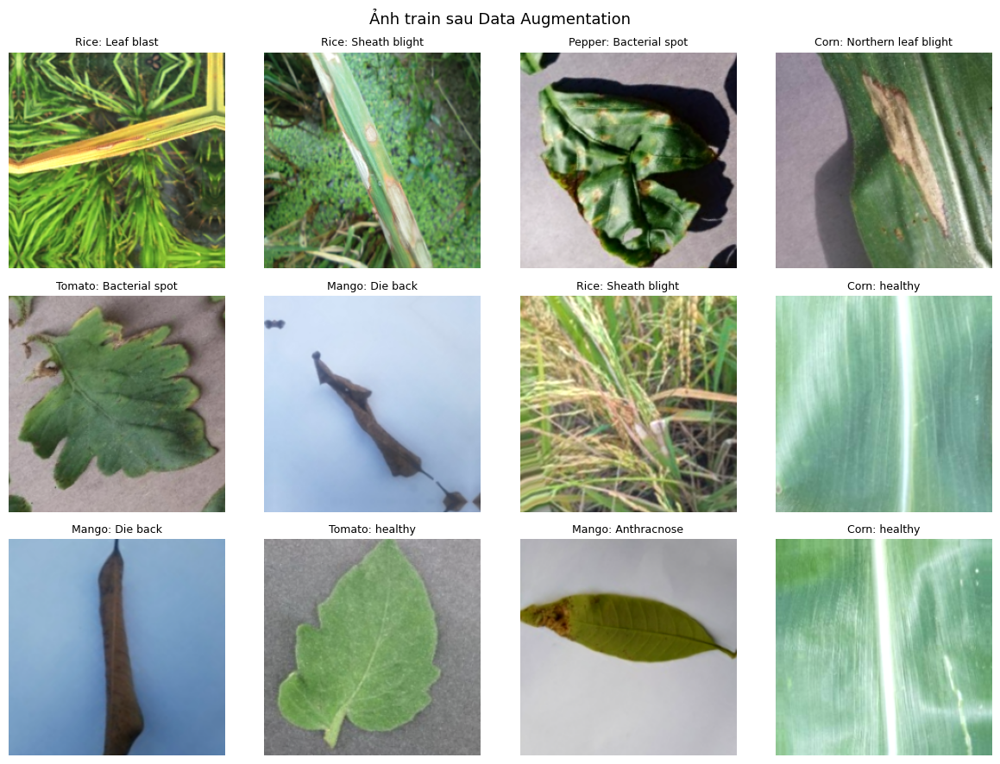

In [ ]:
# ============ CELL 6: XEM THỬ 12 ẢNH TRAIN SAU AUGMENTATION ============
# (Có thể hiện cảnh báo "iterator did not fully read the dataset being cached" — bình thường, bỏ qua.)
plt.figure(figsize=(12, 9))
for imgs, lbls in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(np.clip(imgs[i].numpy(), 0, 255).astype('uint8'))
        plt.title(short_names[int(np.argmax(lbls[i]))], fontsize=9)
        plt.axis('off')
plt.suptitle('Ảnh train sau Data Augmentation', fontsize=13)
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/preview_augmented.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============ CELL 7: THỊ GIÁC MÁY TÍNH — HSV + GRABCUT + ƯỚC LƯỢNG % TỔN THƯƠNG ============
import cv2
import seaborn as sns

# Ngưỡng HSV theo thang OpenCV (H: 0-179, S/V: 0-255). Được chỉnh ban đầu cho lá cà chua:
# hãy kiểm tra từng cây bằng bảng/hình ở Cell 8 rồi mới chốt.
LEAF_GREEN = ((25, 35, 30), (95, 255, 255))    # prior của lá: xanh lá -> vàng-xanh
LEAF_BROWN = ((0, 50, 30), (25, 255, 255))     # vàng/nâu: mô bệnh (chỉ nhận khi dính vào vùng lá xanh)
DARK       = ((0, 0, 0), (179, 255, 70))       # mô hoại tử sẫm/đen (chỉ nhận khi dính vào vùng lá xanh)
HEALTHY    = ((35, 45, 35), (90, 255, 255))    # mô lá khỏe (mô nhạt/vàng-xanh KHÔNG được coi là khỏe)
GLARE      = ((0, 0, 190), (179, 40, 255))     # phản quang trắng sáng: không tính là bệnh
SHADOW_MAX_H = 40    # cụm tối có hue trung vị > ngưỡng này (xanh-tím/xám) bị coi là bóng đổ
SHADOW_MIN_S = 50    # cụm tối có độ bão hòa trung vị < ngưỡng này bị coi là bóng đổ


def _odd(n):
    n = max(3, int(round(n)))
    return n if n % 2 == 1 else n + 1


def _in_range(hsv, rng_):
    return cv2.inRange(hsv, np.array(rng_[0], np.uint8), np.array(rng_[1], np.uint8))


def _fill_and_keep_large(mask, min_ratio=0.10):
    # Giữ các thành phần liên thông lớn (>= min_ratio * thành phần lớn nhất) và lấp lỗ bên trong
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(mask)
    if not cnts:
        return out
    max_area = max(cv2.contourArea(c) for c in cnts)
    keep = [c for c in cnts if cv2.contourArea(c) >= min_ratio * max_area]
    cv2.drawContours(out, keep, -1, 255, thickness=cv2.FILLED)
    return out


def segment_leaf_and_severity(img_bgr, max_side=512):
    # Đầu vào: ảnh BGR (cv2.imread). Trả về dict (hoặc None nếu ảnh lỗi):
    #   img, hsv_prior, leaf_mask, leaf_only, disease_mask, severity (%), method
    if img_bgr is None or img_bgr.size == 0:
        return None

    # Thu nhỏ ảnh lớn (GrabCut rất chậm trên ảnh to); kernel co giãn theo kích thước ảnh
    h0, w0 = img_bgr.shape[:2]
    if max(h0, w0) > max_side:
        r = max_side / max(h0, w0)
        img_bgr = cv2.resize(img_bgr, (int(w0 * r), int(h0 * r)), interpolation=cv2.INTER_AREA)
    img_bgr = np.ascontiguousarray(img_bgr)
    h, w = img_bgr.shape[:2]
    s = max(h, w) / 256.0
    kk = _odd(5 * s)
    k5 = np.ones((kk, kk), np.uint8)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

    # ---- 1) PRIOR từ HSV: vùng xanh = lá; cụm vàng/nâu/sẫm chỉ nhận nếu DÍNH vào lá ----
    green = _in_range(hsv, LEAF_GREEN)
    green = cv2.morphologyEx(green, cv2.MORPH_OPEN, k5)
    green = cv2.morphologyEx(green, cv2.MORPH_CLOSE, k5, iterations=2)
    green = _fill_and_keep_large(green)

    # Mô bệnh nằm ở MÉP lá không được bao quanh bởi vùng xanh, nếu bỏ sót thì sẽ bị cắt khỏi mask lá và
    # % tổn thương bị đánh thấp. Giữ nguyên cả cụm liên thông màu nâu/sẫm khi cụm đó:
    #   (a) dính vào lá, (b) không chạm viền ảnh, (c) không quá lớn so với vùng xanh,
    #   (d) màu nâu/cam/vàng và đủ bão hòa (loại bóng đổ xanh-tím/xám).
    near = cv2.dilate(green, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (_odd(25 * s), _odd(25 * s))))
    lesion_col = cv2.bitwise_or(_in_range(hsv, LEAF_BROWN), _in_range(hsv, DARK))
    lesion_col = cv2.morphologyEx(lesion_col, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n_cc, lab, stats, _ = cv2.connectedComponentsWithStats(lesion_col, connectivity=8)
    green_area = np.count_nonzero(green)
    lesion_keep = np.zeros((h, w), np.uint8)
    for i in np.unique(lab[(near > 0) & (lab > 0)]):                  # (a) cụm giao với vùng sát lá
        x, y, bw, bh, area = stats[i]
        touches_border = x <= 0 or y <= 0 or x + bw >= w or y + bh >= h
        if area >= 20 * s * s and not touches_border and area <= 0.6 * green_area:
            comp = lab == i
            if (np.median(hsv[..., 0][comp]) <= SHADOW_MAX_H and
                    np.median(hsv[..., 1][comp]) >= SHADOW_MIN_S):     # (d) không phải bóng đổ
                lesion_keep[comp] = 255

    prior = cv2.bitwise_or(green, lesion_keep)
    prior = cv2.morphologyEx(prior, cv2.MORPH_CLOSE, k5, iterations=2)
    prior = _fill_and_keep_large(prior)

    # ---- 2) GRABCUT với mặt nạ khởi tạo (GC_INIT_WITH_MASK) ----
    leaf_mask, method = prior.copy(), 'hsv_prior'
    if np.count_nonzero(prior) < 100:
        leaf_mask, method = np.full((h, w), 255, np.uint8), 'full_image'   # không thấy lá xanh -> dùng cả khung
    else:
        gc = np.full((h, w), cv2.GC_BGD, np.uint8)                          # xa lá          -> chắc chắn nền
        gc[cv2.dilate(prior, k5, iterations=3) > 0] = cv2.GC_PR_BGD         # sát lá         -> có thể là nền
        gc[prior > 0] = cv2.GC_PR_FGD                                       # trong prior    -> có thể là lá
        gc[cv2.erode(green, k5, iterations=2) > 0] = cv2.GC_FGD             # lõi vùng xanh  -> chắc chắn lá

        n_fg = np.count_nonzero((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD))
        n_bg = np.count_nonzero((gc == cv2.GC_BGD) | (gc == cv2.GC_PR_BGD))
        if n_fg >= 100 and n_bg >= 100:      # GrabCut cần đủ mẫu cả 2 phía, nếu không sẽ báo lỗi
            try:
                bgd = np.zeros((1, 65), np.float64)
                fgd = np.zeros((1, 65), np.float64)
                cv2.grabCut(img_bgr, gc, None, bgd, fgd, 5, cv2.GC_INIT_WITH_MASK)
                gc_fg = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
                gc_fg = _fill_and_keep_large(cv2.bitwise_or(gc_fg, lesion_keep))   # GrabCut không được cắt mất mô bệnh
                cover = np.count_nonzero(cv2.bitwise_and(gc_fg, green)) / max(1, np.count_nonzero(green))
                if cover >= 0.5 and np.count_nonzero(gc_fg) >= 0.02 * h * w:   # kết quả hợp lý mới nhận
                    leaf_mask, method = gc_fg, 'grabcut'
            except cv2.error:
                pass                                                          # giữ prior HSV

    # Bù các vết hoại tử lớn bị khoét khỏi mask lá (rãnh/lỗ hẹp bên trong lá được lấp lại)
    if method != 'full_image':
        big = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (_odd(31 * s), _odd(31 * s)))
        leaf_mask = _fill_and_keep_large(cv2.morphologyEx(leaf_mask, cv2.MORPH_CLOSE, big))

    leaf_only = cv2.bitwise_and(img_bgr, img_bgr, mask=leaf_mask)

    # ---- 3) Tách mô khỏe / mô bệnh trong lá, tính % diện tích ----
    # Bỏ viền lá vài pixel vì pixel viền bị pha màu nền -> dễ bị tính nhầm là bệnh
    core = cv2.erode(leaf_mask, np.ones((3, 3), np.uint8), iterations=max(1, int(round(3 * s))))
    not_disease = cv2.bitwise_or(_in_range(hsv, HEALTHY), _in_range(hsv, GLARE))
    disease = cv2.bitwise_and(core, cv2.bitwise_not(not_disease))
    disease = cv2.morphologyEx(disease, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))   # bỏ nhiễu/gân lá mảnh

    leaf_area = np.count_nonzero(core)
    severity = 100.0 * np.count_nonzero(disease) / leaf_area if leaf_area > 0 else 0.0
    if method == 'full_image':
        severity = float('nan')      # không tách được lá -> không có căn cứ để tính %, tránh trả số sai (vd 100%)
    return {'img': img_bgr, 'hsv_prior': prior, 'leaf_mask': leaf_mask, 'leaf_only': leaf_only,
            'disease_mask': disease, 'severity': float(severity), 'method': method}


def fmt_sev(sev):
    return 'N/A' if np.isnan(sev) else f'{sev:.1f}%'


def severity_grade(sev):
    # Ngưỡng phân mức mang tính tham khảo (heuristic), không phải chuẩn nông học
    if np.isnan(sev):
        return 'Không xác định (không tách được lá)'
    if sev < 5:
        return 'Rất nhẹ / khỏe'
    if sev < 15:
        return 'Nhẹ'
    if sev < 40:
        return 'Trung bình'
    return 'Nặng'


def severity_overlay(res):
    # Ảnh RGB: pixel bệnh tô đỏ, viền lá màu xanh
    vis = res['img'].copy()
    m = res['disease_mask'] > 0
    red = np.zeros_like(vis)
    red[:] = (0, 0, 255)
    vis[m] = (0.5 * vis[m] + 0.5 * red[m]).astype(np.uint8)
    cnts, _ = cv2.findContours(res['leaf_mask'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnts, -1, (0, 255, 0), 2)
    return cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)


def cv_steps_figure(items, save_name=None):
    # items: list[(tiêu đề, ảnh BGR)] -> mỗi ảnh 1 hàng, 5 cột hiển thị từng bước xử lý
    heads = ['Ảnh gốc', 'Mask HSV (prior)', 'Mask lá (sau GrabCut)', 'Lá đã tách nền', 'Vùng bệnh (đỏ)']
    fig, axes = plt.subplots(len(items), 5, figsize=(18, 3.7 * len(items)))
    axes = np.atleast_2d(axes)
    for r, (title, img) in enumerate(items):
        res = segment_leaf_and_severity(img)
        if res is None:
            continue
        panels = [cv2.cvtColor(res['img'], cv2.COLOR_BGR2RGB), res['hsv_prior'], res['leaf_mask'],
                  cv2.cvtColor(res['leaf_only'], cv2.COLOR_BGR2RGB), severity_overlay(res)]
        titles = [f"{title}\n{heads[0]}", heads[1], f"{heads[2]}\n[{res['method']}]", heads[3],
                  f"{heads[4]} | {fmt_sev(res['severity'])}"]
        for c in range(5):
            if panels[c].ndim == 2:
                axes[r, c].imshow(panels[c], cmap='gray', vmin=0, vmax=255)
            else:
                axes[r, c].imshow(panels[c])
            axes[r, c].set_title(titles[c], fontsize=10)
            axes[r, c].axis('off')
    plt.tight_layout()
    if save_name:
        plt.savefig(f'{DRIVE_DIR}/{save_name}', dpi=200, bbox_inches='tight')
    plt.show()

print("Đã định nghĩa segment_leaf_and_severity() — kiểm chứng ở Cell 8.")

Đã định nghĩa segment_leaf_and_severity() — kiểm chứng ở Cell 8.


=== % DIỆN TÍCH TỔN THƯƠNG THEO LỚP (mẫu từ tập val) ===
                               crop  count   mean  median    std
class                                                           
Corn: Common rust              Corn     25  28.11   22.01  19.54
Corn: Gray leaf spot           Corn     25  28.77   25.21  13.87
Corn: Northern leaf blight     Corn     25  25.79   22.98  12.83
Corn: healthy                  Corn     25   0.74    0.38   0.96
Mango: Anthracnose            Mango     20  54.75   59.28  41.54
Mango: Bacterial canker       Mango     25  56.63   51.57  27.06
Mango: Cutting weevil         Mango     25  24.89   23.90  13.92
Mango: Die back               Mango      3  63.84   91.57  55.45
Mango: Gall midge             Mango     25  47.84   51.33  20.20
Mango: Powdery mildew         Mango     25  50.25   53.53  30.32
Mango: Sooty mould            Mango     25  72.43   85.44  24.90
Mango: healthy                Mango     25   1.16    0.16   3.78
Pepper: Bacterial spot       Pepp

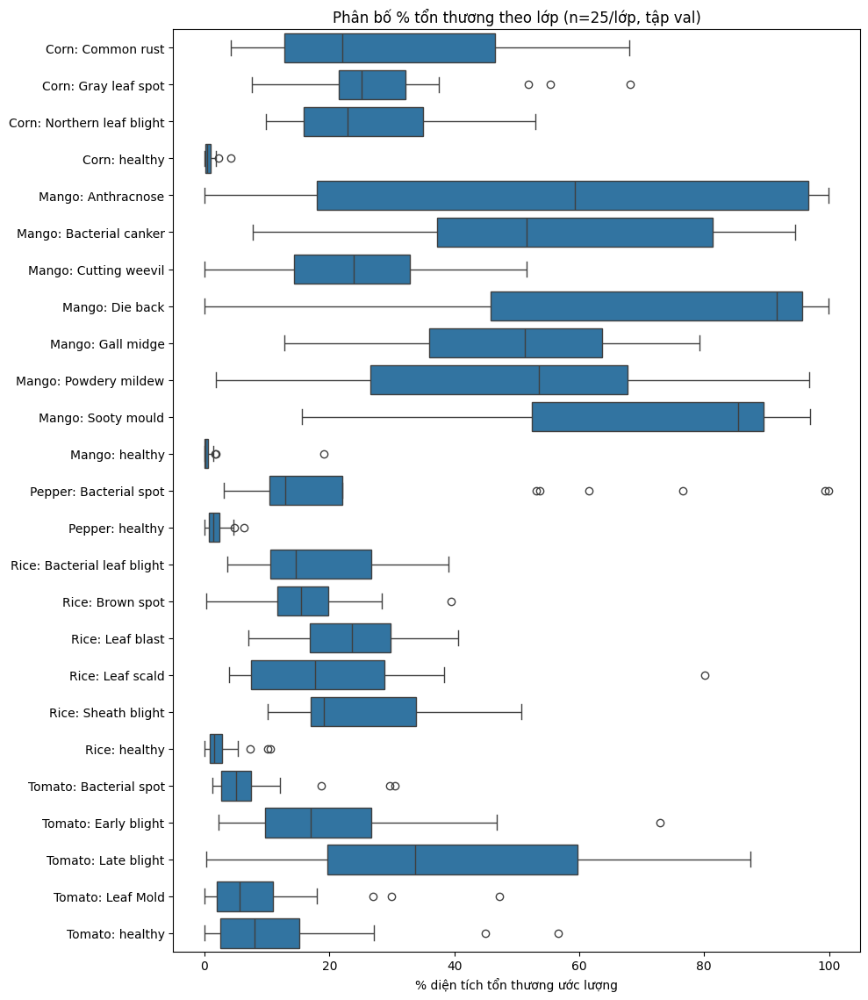

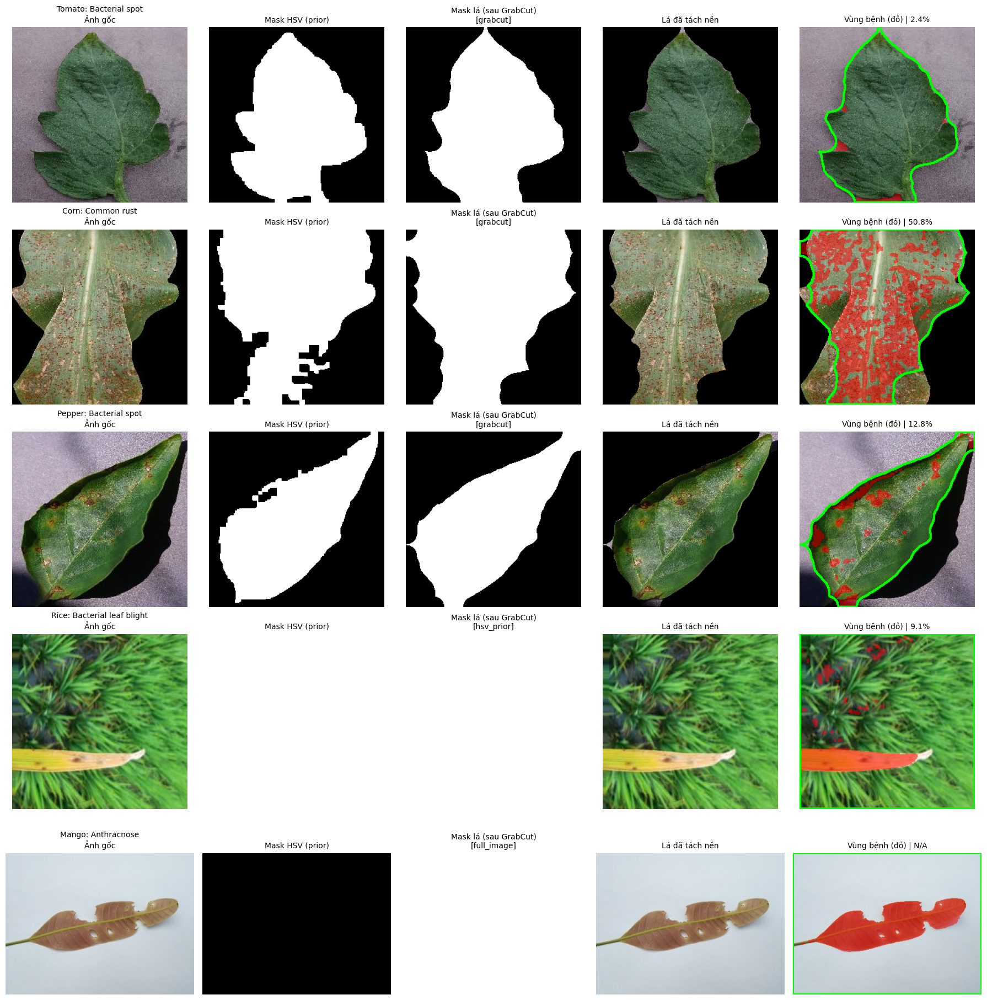

In [ ]:
# ============ CELL 8: KIỂM CHỨNG THỊ GIÁC MÁY TÍNH THEO TỪNG CÂY (trên tập VAL) ============
N_PER_CLASS = 25
rng = random.Random(SEED)
rows = []
for ci, cname in enumerate(class_names):
    d = os.path.join(SPLIT_ROOT, 'val', cname)
    fl = sorted(os.listdir(d))
    rng.shuffle(fl)
    for f in fl[:N_PER_CLASS]:
        res = segment_leaf_and_severity(cv2.imread(os.path.join(d, f)))
        if res is not None:
            rows.append((class_crops[ci], short_names[ci], res['severity'], res['method']))

df_sev = pd.DataFrame(rows, columns=['crop', 'class', 'severity', 'method'])
summary = (df_sev.groupby('class')['severity'].agg(['count', 'mean', 'median', 'std']).round(2)
           .reindex(short_names))
summary.insert(0, 'crop', class_crops)
print("=== % DIỆN TÍCH TỔN THƯƠNG THEO LỚP (mẫu từ tập val) ===")
print(summary.to_string())
print("\n=== Phương pháp tách lá theo cây (grabcut = thành công; hsv_prior/full_image = dự phòng) ===")
print(pd.crosstab(df_sev['crop'], df_sev['method']))
summary.to_csv(f'{DRIVE_DIR}/severity_by_class.csv')

print("\n=== KIỂM TRA THEO CÂY: lá khỏe phải thấp, lá bệnh phải cao hơn ===")
for crop in CROPS:
    idx_h = [i for i in range(NUM_CLASSES) if class_crops[i] == crop and is_healthy(i)]
    idx_d = [i for i in range(NUM_CLASSES) if class_crops[i] == crop and not is_healthy(i)]
    if not idx_h or not idx_d:
        print(f"  {crop:7s}: không có đủ lớp khỏe/bệnh để so sánh")
        continue
    mh = summary.loc[short_names[idx_h[0]], 'median']
    md = np.nanmedian([summary.loc[short_names[i], 'median'] for i in idx_d])
    print(f"  {crop:7s}: median lá khỏe = {mh:5.1f}% | median các lớp bệnh = {md:5.1f}%")
    if np.isnan(mh) or np.isnan(md):
        print("     ⚠️ Có lớp không tách được lá (N/A) — xem hình cv_steps của cây này.")
        continue
    if mh > 3:
        print(f"     ⚠️ Lá khỏe của {crop} ra % cao: kiểm tra bóng đổ/ngưỡng HEALTHY (Cell 7).")
    if md <= mh:
        print(f"     ⚠️ Lá bệnh của {crop} không cao hơn lá khỏe: ngưỡng HSV chưa phù hợp với cây này.")

plt.figure(figsize=(10, 0.38 * NUM_CLASSES + 2))
sns.boxplot(data=df_sev, y='class', x='severity', order=short_names, orient='h')
plt.xlabel('% diện tích tổn thương ước lượng')
plt.ylabel('')
plt.title(f'Phân bố % tổn thương theo lớp (n={N_PER_CLASS}/lớp, tập val)')
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/severity_by_class.png', dpi=200, bbox_inches='tight')
plt.show()

# Từng bước xử lý: 1 ảnh bệnh cho mỗi cây
items = []
for crop in CROPS:
    ids = [i for i in range(NUM_CLASSES) if class_crops[i] == crop and not is_healthy(i)]
    if not ids:
        continue
    d = os.path.join(SPLIT_ROOT, 'val', class_names[ids[0]])
    items.append((short_names[ids[0]], cv2.imread(os.path.join(d, sorted(os.listdir(d))[0]))))
cv_steps_figure(items, save_name='cv_steps.png')

In [ ]:
# ============ CELL 9: XÂY DỰNG MÔ HÌNH EfficientNetB0 ============
# (Không bật mixed precision: sẽ làm Grad-CAM++ ở Cell 13 dễ lỗi số học / sai lệch.)
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', input_shape=(224, 224, 3), name='efficientnetb0')
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')
# KHÔNG gọi preprocess_input: EfficientNetB0 đã có sẵn Rescaling/Normalization bên trong, nhận ảnh 0-255.
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
x = tf.keras.layers.Dropout(0.5, name='top_dropout')(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

model = tf.keras.Model(inputs, outputs, name='plant_disease_model')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "plant_disease_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 25)             │        32,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,081,596 (15.57 MB)

 Trainable params: 32,025 (125.10 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# ============ CELL 10: PHA 1 — WARM-UP (ĐÓNG BĂNG BASE MODEL) ============
WARMUP_EPOCHS = 4
history1 = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS,
                     class_weight=class_weights, verbose=1)

Epoch 1/4
137/137 ━━━━━━━━━━━━━━━━━━━━ 247s 1s/step - accuracy: 0.6024 - loss: 1.3719 - val_accuracy: 0.8101 - val_loss: 0.6772
Epoch 2/4
137/137 ━━━━━━━━━━━━━━━━━━━━ 112s 810ms/step - accuracy: 0.8001 - loss: 0.6460 - val_accuracy: 0.8581 - val_loss: 0.4906
Epoch 3/4
137/137 ━━━━━━━━━━━━━━━━━━━━ 166s 996ms/step - accuracy: 0.8349 - loss: 0.5151 - val_accuracy: 0.8773 - val_loss: 0.4120
Epoch 4/4
137/137 ━━━━━━━━━━━━━━━━━━━━ 115s 800ms/step - accuracy: 0.8529 - loss: 0.4521 - val_accuracy: 0.8912 - val_loss: 0.3660


In [ ]:
# ============ CELL 11: PHA 2 — FINE-TUNING ============
FT_LAYERS = 60       # số lớp cuối của EfficientNetB0 được mở khóa
FT_LR     = 3e-5     # learning rate fine-tune
FT_EPOCHS = 20       # tối đa; EarlyStopping có thể dừng sớm

base_model.trainable = True
for layer in base_model.layers[:-FT_LAYERS]:
    layer.trainable = False
for layer in base_model.layers[-FT_LAYERS:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False          # giữ BatchNorm đóng băng để fine-tune ổn định
print("Số tensor trọng số huấn luyện được:", len(model.trainable_weights))

model.compile(optimizer=tf.keras.optimizers.Adam(FT_LR),     # compile lại sau khi đổi trainable
              loss='categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(CKPT_PATH, save_best_only=True,
                                       monitor='val_loss', mode='min', verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=6,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', patience=3,
                                         factor=0.5, verbose=1),
]
history2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS,
                     class_weight=class_weights, callbacks=callbacks, verbose=1)

Số tensor trọng số huấn luyện được: 30
Epoch 1/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8698 - loss: 0.3874   
Epoch 1: val_loss improved from None to 0.27304, saving model to /content/best_model.keras

Epoch 1: finished saving model to /content/best_model.keras
137/137 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.8723 - loss: 0.3665 - val_accuracy: 0.9029 - val_loss: 0.2730 - learning_rate: 3.0000e-05
Epoch 2/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 772ms/step - accuracy: 0.8846 - loss: 0.3167
Epoch 2: val_loss improved from 0.27304 to 0.24457, saving model to /content/best_model.keras

Epoch 2: finished saving model to /content/best_model.keras
137/137 ━━━━━━━━━━━━━━━━━━━━ 110s 793ms/step - accuracy: 0.8903 - loss: 0.3061 - val_accuracy: 0.9136 - val_loss: 0.2446 - learning_rate: 3.0000e-05
Epoch 3/20
137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 778ms/step - accuracy: 0.8956 - loss: 0.2890
Epoch 3: val_loss improved from 0.24457 to 0.22579, saving model to /content/best_model.keras



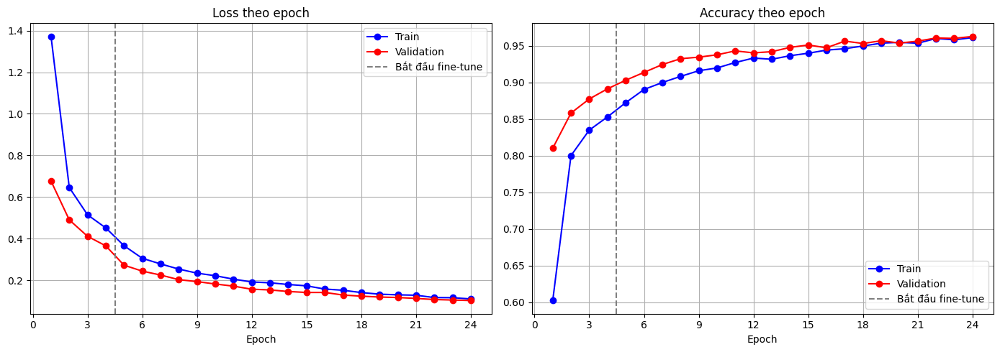

30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 304ms/step

Test accuracy (đúng cả cây lẫn bệnh): 0.9659  (1811/1875)

=== CLASSIFICATION REPORT (TEST) ===
                             precision    recall  f1-score   support

          Corn: Common rust     1.0000    1.0000    1.0000        75
       Corn: Gray leaf spot     0.9701    0.8667    0.9155        75
 Corn: Northern leaf blight     0.8795    0.9733    0.9241        75
              Corn: healthy     1.0000    1.0000    1.0000        75
         Mango: Anthracnose     1.0000    1.0000    1.0000        75
    Mango: Bacterial canker     0.9868    1.0000    0.9934        75
      Mango: Cutting weevil     1.0000    1.0000    1.0000        75
            Mango: Die back     1.0000    1.0000    1.0000        75
          Mango: Gall midge     1.0000    1.0000    1.0000        75
      Mango: Powdery mildew     1.0000    0.9867    0.9933        75
         Mango: Sooty mould     0.9868    1.0000    0.9934        75
             Mango: healthy     

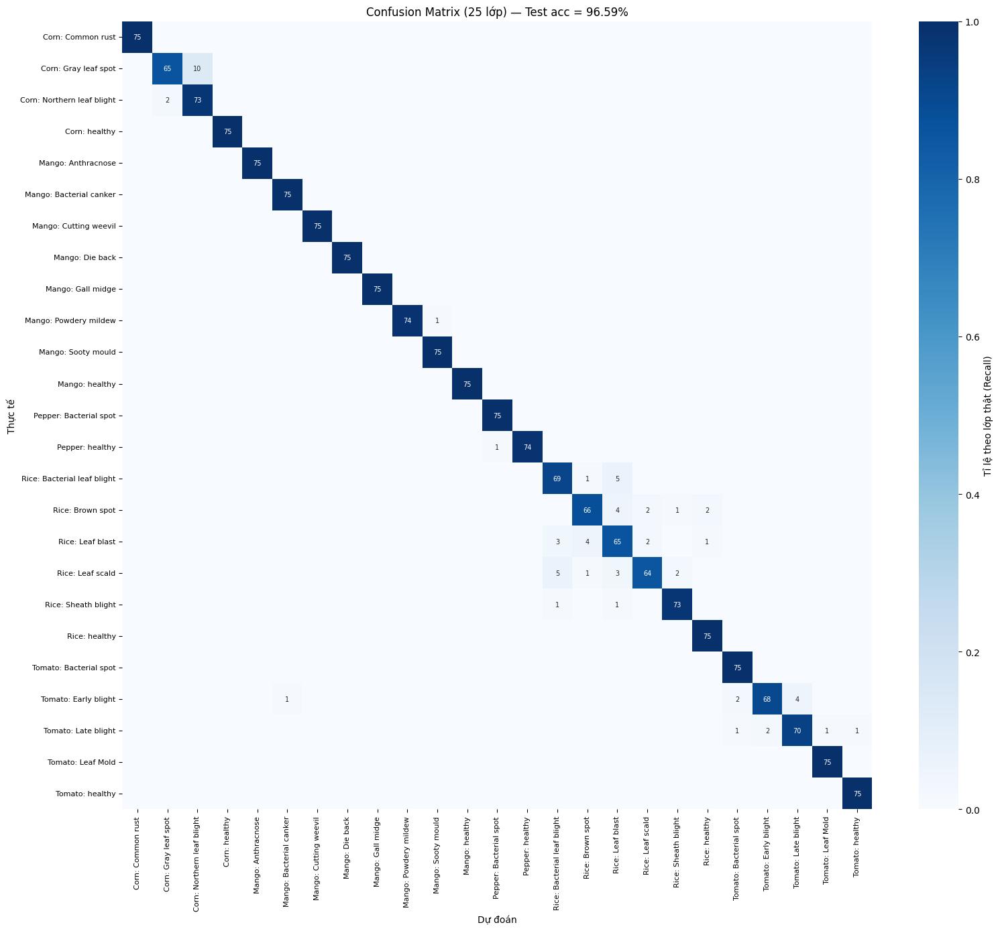

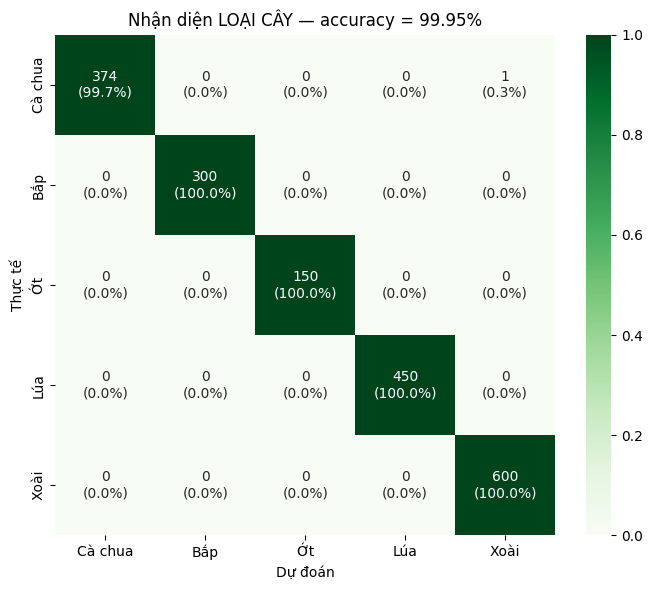


=== KẾT QUẢ THEO CÂY (TEST) ===
  crop  n_test  acc_cay_va_benh  acc_nhan_dien_cay  acc_benh_khi_dung_cay
Tomato     375           0.9680             0.9973                 0.9706
  Corn     300           0.9600             1.0000                 0.9600
Pepper     150           0.9933             1.0000                 0.9933
  Rice     450           0.9156             1.0000                 0.9156
 Mango     600           0.9983             1.0000                 0.9983

Top-5 cặp nhầm lẫn:
   10 ảnh | Thực tế: Corn: Gray leaf spot           -> Dự đoán: Corn: Northern leaf blight
    5 ảnh | Thực tế: Rice: Leaf scald               -> Dự đoán: Rice: Bacterial leaf blight
    5 ảnh | Thực tế: Rice: Bacterial leaf blight    -> Dự đoán: Rice: Leaf blast
    4 ảnh | Thực tế: Tomato: Early blight           -> Dự đoán: Tomato: Late blight
    4 ảnh | Thực tế: Rice: Leaf blast               -> Dự đoán: Rice: Brown spot


In [ ]:
# ============ CELL 12: ĐÁNH GIÁ TRÊN TẬP TEST + XUẤT BÁO CÁO ============
from sklearn.metrics import classification_report, confusion_matrix

model = tf.keras.models.load_model(CKPT_PATH)     # luôn đánh giá đúng bộ trọng số tốt nhất

# --- 1) Biểu đồ lịch sử huấn luyện (Loss / Accuracy) ---
h1, h2 = history1.history, history2.history
hist = pd.DataFrame({k: h1[k] + h2[k] for k in ['loss', 'accuracy', 'val_loss', 'val_accuracy']})
hist['phase'] = ['warmup'] * len(h1['loss']) + ['finetune'] * len(h2['loss'])
hist.index = range(1, len(hist) + 1)
hist.index.name = 'epoch'
hist.to_csv(f'{DRIVE_DIR}/training_history.csv')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (tr, va, title) in zip(ax, [('loss', 'val_loss', 'Loss'), ('accuracy', 'val_accuracy', 'Accuracy')]):
    a.plot(hist.index, hist[tr], 'b-o', label='Train')
    a.plot(hist.index, hist[va], 'r-o', label='Validation')
    a.axvline(len(h1['loss']) + 0.5, color='gray', ls='--', label='Bắt đầu fine-tune')
    a.set_title(f'{title} theo epoch'); a.set_xlabel('Epoch'); a.legend(); a.grid(True)
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/history_loss_acc.png', dpi=200, bbox_inches='tight')
plt.show()

# --- 2) Dự đoán trên TEST ---
y_true = np.concatenate([np.argmax(y.numpy(), 1) for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, 1)

assert len(test_files) == len(y_true), "Danh sách file test không khớp số mẫu test!"
for f, t in zip(test_files, y_true):             # kiểm tra thứ tự file <-> nhãn
    assert os.path.basename(os.path.dirname(f)) == class_names[t], "Lệch thứ tự file test!"

test_acc_cell12 = float(np.mean(y_true == y_pred))
print(f"\nTest accuracy (đúng cả cây lẫn bệnh): {test_acc_cell12:.4f}  ({int((y_true == y_pred).sum())}/{len(y_true)})")

# --- 3) Precision / Recall / F1 theo từng lớp ---
labels_all = np.arange(NUM_CLASSES)
print("\n=== CLASSIFICATION REPORT (TEST) ===")
print(classification_report(y_true, y_pred, labels=labels_all, target_names=short_names, digits=4, zero_division=0))
rep = classification_report(y_true, y_pred, labels=labels_all, target_names=short_names, digits=4,
                            zero_division=0, output_dict=True)
pd.DataFrame(rep).transpose().to_csv(f'{DRIVE_DIR}/classification_report.csv')

# --- 4) Confusion Matrix theo lớp (màu = recall, số = số ảnh, ô 0 để trống) ---
cm = confusion_matrix(y_true, y_pred, labels=labels_all)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
annot = np.where(cm > 0, cm.astype(str), '')
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, annot_kws={'size': 7},
            xticklabels=short_names, yticklabels=short_names, cbar_kws={'label': 'Tỉ lệ theo lớp thật (Recall)'}, ax=ax)
ax.set_title(f'Confusion Matrix ({NUM_CLASSES} lớp) — Test acc = {test_acc_cell12:.2%}')
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
ax.tick_params(axis='x', rotation=90, labelsize=8); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

# --- 5) Mức "cây": mô hình có nhận đúng loại cây không? ---
crop_idx = np.array([CROPS.index(c) for c in class_crops])
yt_c, yp_c = crop_idx[y_true], crop_idx[y_pred]
cm_c = confusion_matrix(yt_c, yp_c, labels=np.arange(len(CROPS)))
cm_c_pct = cm_c / np.maximum(cm_c.sum(axis=1, keepdims=True), 1)
annot_c = np.array([[f"{cm_c[i, j]}\n({cm_c_pct[i, j]:.1%})" for j in range(len(CROPS))] for i in range(len(CROPS))])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_c_pct, annot=annot_c, fmt='', cmap='Greens', vmin=0, vmax=1,
            xticklabels=[CROP_VI[c] for c in CROPS], yticklabels=[CROP_VI[c] for c in CROPS], ax=ax)
ax.set_title(f'Nhận diện LOẠI CÂY — accuracy = {np.mean(yt_c == yp_c):.2%}')
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
plt.tight_layout()
plt.savefig(f'{DRIVE_DIR}/confusion_matrix_crop.png', dpi=200, bbox_inches='tight')
plt.show()

rows = []
for ci, c in enumerate(CROPS):
    m = yt_c == ci
    m_ok = m & (yp_c == ci)
    rows.append((c, int(m.sum()), float(np.mean(y_pred[m] == y_true[m])), float(np.mean(yp_c[m] == ci)),
                 float(np.mean(y_pred[m_ok] == y_true[m_ok])) if m_ok.any() else float('nan')))
df_crop = pd.DataFrame(rows, columns=['crop', 'n_test', 'acc_cay_va_benh', 'acc_nhan_dien_cay', 'acc_benh_khi_dung_cay'])
print("\n=== KẾT QUẢ THEO CÂY (TEST) ===")
print(df_crop.round(4).to_string(index=False))
df_crop.to_csv(f'{DRIVE_DIR}/per_crop_summary.csv', index=False)

# --- 6) Top-5 cặp nhầm lẫn ---
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = sorted([(cm_off[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j], reverse=True)
print("\nTop-5 cặp nhầm lẫn:")
for c, i, j in pairs[:5]:
    print(f"  {c:3d} ảnh | Thực tế: {short_names[i]:30s} -> Dự đoán: {short_names[j]}")

### Nhận xét kết quả (Cell 12)

**Độ chính xác tổng thể:**
- Test accuracy (đúng cả cây lẫn bệnh) = **96.59%** (1811/1875 ảnh), macro F1 = **0.9657**, weighted F1 = **0.9657**.
- Độ chính xác nhận diện **loại cây**: Bắp 100%, Ớt 100%, Lúa 100%, Xoài 100%, Cà chua 99.73% → trung bình **~99.95%**.

**Kết quả theo từng cây:**

| Cây | Số ảnh test | Acc (cây + bệnh) | Acc nhận diện cây | Acc bệnh khi đúng cây |
|---|---|---|---|---|
| Cà chua | 375 | 96.80% | 99.73% | 97.06% |
| Bắp | 300 | 96.00% | 100.00% | 96.00% |
| Ớt | 150 | 99.33% | 100.00% | 99.33% |
| Lúa | 450 | 91.56% | 100.00% | 91.56% |
| Xoài | 600 | 99.83% | 100.00% | 99.83% |

- Cây có kết quả tốt nhất: **Xoài** (99.83%) và **Ớt** (99.33%).
- Cây có kết quả yếu nhất: **Lúa** (91.56%), do các lớp bệnh lúa có hình thái tương đồng nhau (xem phân tích lỗi bên dưới).

**Lớp có F1 thấp nhất:**
- **Rice: Leaf blast** (F1 = 0.8497, Recall = 0.8667): bệnh đạo ôn có triệu chứng gần giống đốm nâu và bạc lá.
- **Rice: Bacterial leaf blight** (F1 = 0.9020, Recall = 0.9200): hay nhầm với Leaf blast.
- **Corn: Gray leaf spot** (F1 = 0.9155, Recall = 0.8667): hay nhầm với Northern leaf blight.

**Top-5 cặp nhầm lẫn nhiều nhất:**

| Số ảnh nhầm | Thực tế | Dự đoán |
|---|---|---|
| 10 | Corn: Gray leaf spot | Corn: Northern leaf blight |
| 5 | Rice: Leaf scald | Rice: Bacterial leaf blight |
| 5 | Rice: Bacterial leaf blight | Rice: Leaf blast |
| 4 | Tomato: Early blight | Tomato: Late blight |
| 4 | Rice: Leaf blast | Rice: Brown spot |

- Lỗi chủ yếu xảy ra trong **cùng một cây** (đặc biệt là Lúa và Bắp), không phải nhầm sang cây khác. Điều này cho thấy mô hình đã học được đặc trưng riêng của từng loại cây rất tốt, nhưng còn khó phân biệt các bệnh có hình thái tương đồng (ví dụ đốm xám và cháy lá lớn ở Bắp; đạo ôn, bạc lá, đốm nâu ở Lúa; đốm sớm và đốm muộn ở Cà chua).

**Lưu ý khi diễn giải:**
- Mỗi cây đến từ một bộ dữ liệu khác nhau (nền ảnh, camera, ánh sáng khác nhau), nên độ chính xác nhận diện cây gần 100% một phần có thể nhờ đặc trưng của bộ dữ liệu (nền ảnh, màu sắc tổng thể), không chỉ nhờ hình thái lá thực sự.
- Val accuracy thường cao hơn train accuracy trên biểu đồ vì Dropout 0.5 và augmentation chỉ áp cho tập train, và chỉ số train là trung bình trong suốt epoch (bao gồm cả lúc mô hình chưa hội tụ).
- PlantVillage và một số bộ dữ liệu có nhiều ảnh của cùng một chiếc lá ở các góc xoay khác nhau; chia ngẫu nhiên có thể để ảnh gần giống nhau rơi vào cả train và test, làm accuracy cao hơn thực tế ngoài đồng.

In [ ]:
# ============ CELL 13: GRAD-CAM++ (TÍNH TRÊN LOGIT TRƯỚC SOFTMAX) ============
model = tf.keras.models.load_model(CKPT_PATH)
model.trainable = False

# Tách model: [EfficientNetB0 lồng bên trong] -> [GAP -> Dropout -> Dense(softmax)]
base = model.get_layer('efficientnetb0')
head_layers = model.layers[model.layers.index(base) + 1:]
conv_extractor = tf.keras.Model(base.input, base.get_layer('top_activation').output)   # feature map 7x7x1280

# Bản sao Dense cuối nhưng bỏ softmax -> lấy logit. (Softmax bão hòa ~1.0 làm gradient ≈ 0 ở ảnh dễ.)
dense_w = head_layers[-1].get_weights()
logit_dense = tf.keras.layers.Dense(dense_w[0].shape[1], activation=None)
logit_dense.build((None, dense_w[0].shape[0]))
logit_dense.set_weights(dense_w)


def forward_logits(conv):
    x = conv
    for l in head_layers[:-1]:
        if isinstance(l, tf.keras.layers.Dropout):
            continue                      # Dropout = phép đồng nhất khi suy luận
        x = l(x)
    return logit_dense(x)


# Kiểm tra: tách model làm 2 nửa vẫn cho cùng xác suất với model gốc
_dummy = (np.random.rand(1, 224, 224, 3) * 255).astype('float32')
p_full = model(_dummy).numpy()
p_split = tf.nn.softmax(forward_logits(conv_extractor(_dummy))).numpy()
assert np.allclose(p_full, p_split, atol=1e-4), "Sanity check Grad-CAM++ thất bại: model tách đôi cho kết quả khác!"
print("Sanity check OK — sẵn sàng Grad-CAM++.")


def grad_cam_plus_plus(img_rgb_224_uint8, class_idx=None):
    # Đầu vào: ảnh RGB 224x224, giá trị 0-255. Trả về (cam 224x224 trong [0,1], xác suất (1,C), chỉ số lớp)
    x = tf.convert_to_tensor(np.expand_dims(img_rgb_224_uint8.astype(np.float32), 0))
    conv = conv_extractor(x, training=False)
    with tf.GradientTape() as tape:
        tape.watch(conv)
        logits = forward_logits(conv)
        if class_idx is None:
            class_idx = int(tf.argmax(logits[0]))
        score = logits[:, class_idx]
    grads = tape.gradient(score, conv)
    preds = tf.nn.softmax(logits).numpy()

    g = grads.numpy()[0]                  # (7,7,1280)
    A = conv.numpy()[0]
    g2, g3 = g ** 2, g ** 3
    sumA = A.sum(axis=(0, 1), keepdims=True)
    denom = 2.0 * g2 + sumA * g3
    denom = np.where(denom != 0, denom, 1e-8)
    alpha = np.where(g != 0, g2 / denom, 0.0)
    weights = (alpha * np.maximum(g, 0)).sum(axis=(0, 1))

    cam = np.maximum((weights * A).sum(axis=-1), 0)
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam.astype(np.float32), (224, 224))
    return cam, preds, class_idx

Sanity check OK — sẵn sàng Grad-CAM++.



--- Tomato: Bacterial spot ---


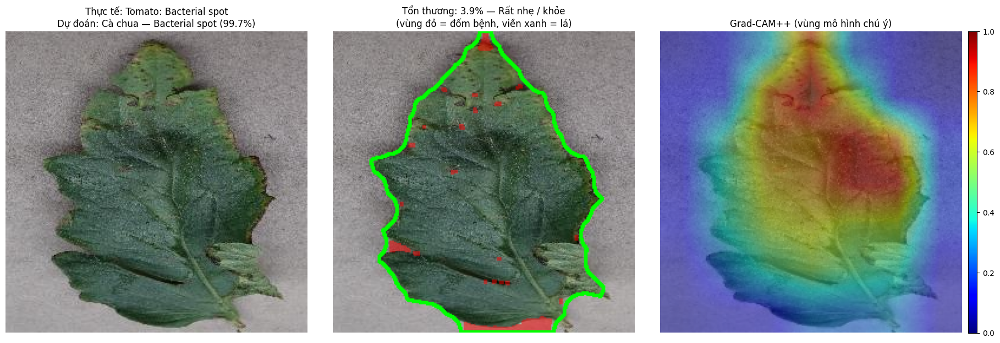


--- Tomato: healthy ---


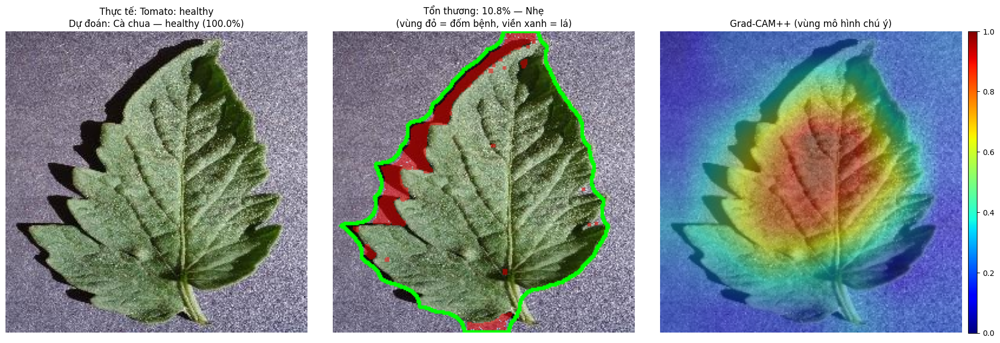


--- Corn: Common rust ---


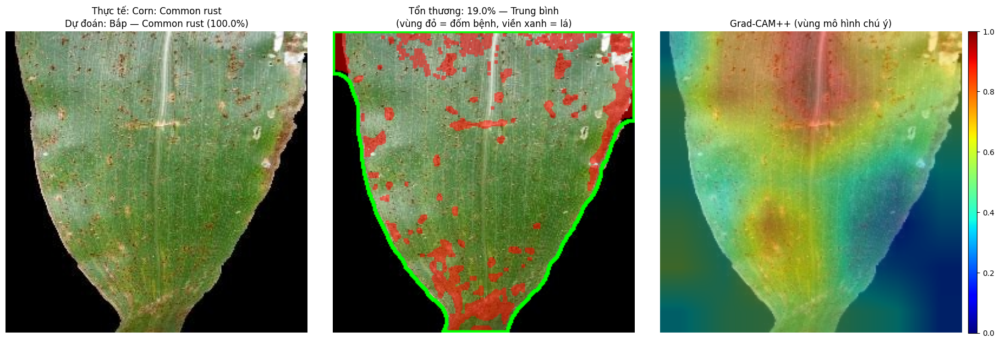


--- Corn: healthy ---


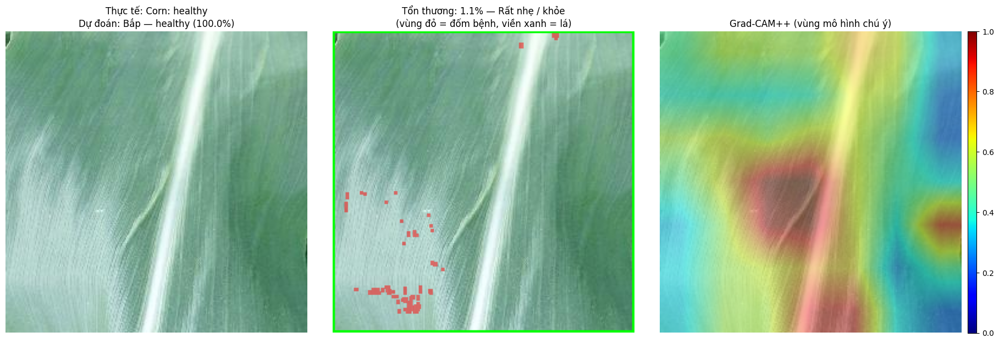


--- Pepper: Bacterial spot ---


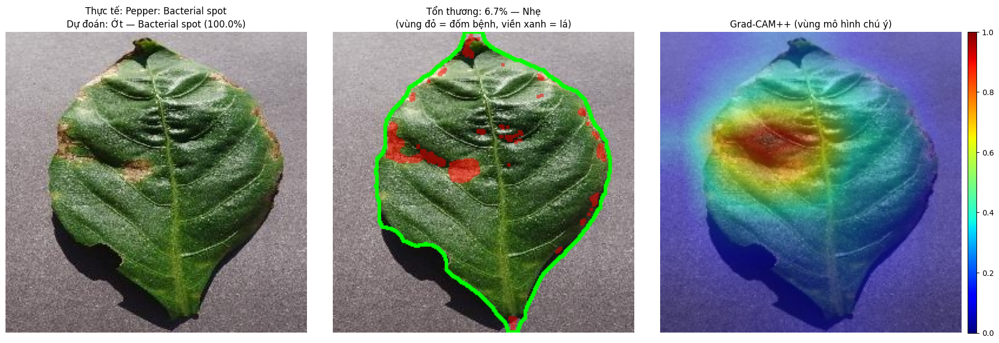


--- Pepper: healthy ---


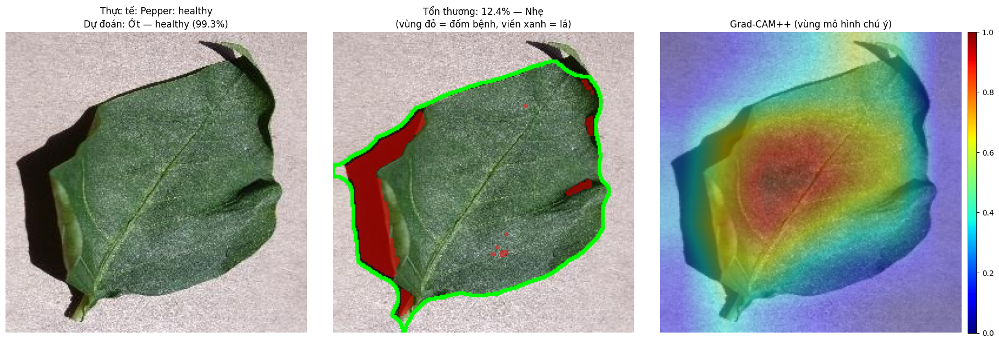


--- Rice: Bacterial leaf blight ---


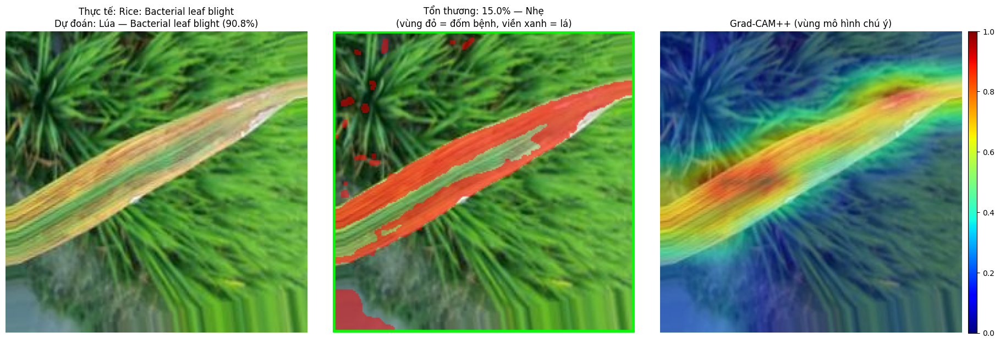


--- Rice: healthy ---


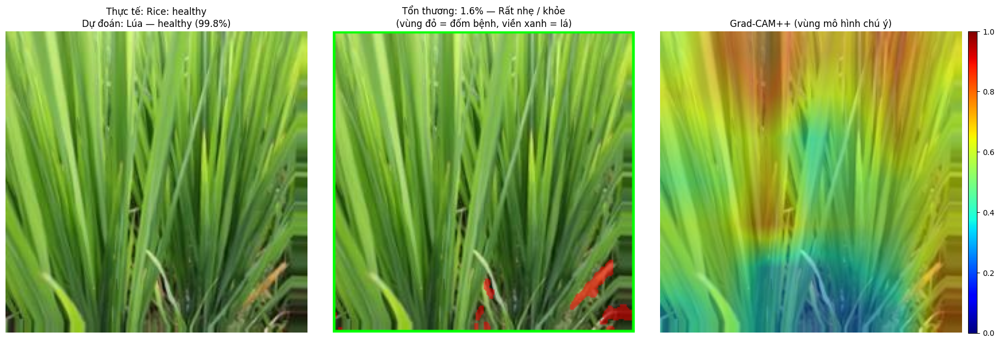


--- Mango: Anthracnose ---


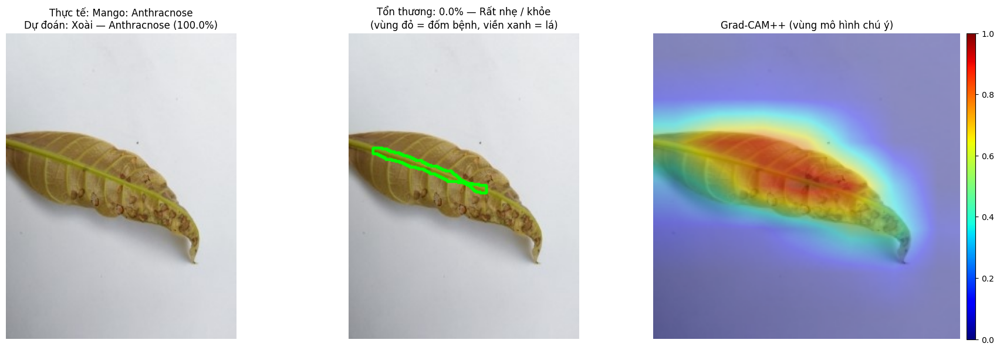


--- Mango: healthy ---


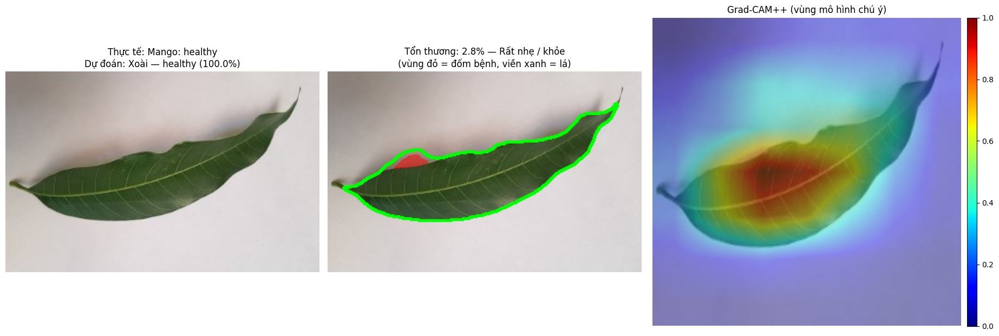

  crop                        true                        pred  confidence  severity_%          grade seg_method                                               file
Tomato      Tomato: Bacterial spot      Tomato: Bacterial spot      0.9970        3.86 Rất nhẹ / khỏe    grabcut 00000_be344c1c-8799-4065-bd7a-d94dd7873520___G.jpg
Tomato             Tomato: healthy             Tomato: healthy      1.0000       10.77            Nhẹ    grabcut 00000_95abb641-4435-4531-88f6-a4a597c5ff33___R.jpg
  Corn           Corn: Common rust           Corn: Common rust      0.9999       19.02     Trung bình    grabcut                             00000_RS_Rust_2514.jpg
  Corn               Corn: healthy               Corn: healthy      1.0000        1.06 Rất nhẹ / khỏe    grabcut 00000_9275afa7-daf0-4052-b092-47d36132e69d___R.jpg
Pepper      Pepper: Bacterial spot      Pepper: Bacterial spot      1.0000        6.68            Nhẹ    grabcut 00000_6d15afc9-3066-4ce4-811c-97da31711bf3___N.jpg
Pepper          

In [ ]:
# ============ CELL 14: PIPELINE SUY LUẬN + DEMO CHO TỪNG CÂY (chỉ ảnh dự đoán ĐÚNG) ============
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


def overlay_heatmap(img_rgb, cam, alpha=0.4):
    heat = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    out = img_rgb.astype(np.float32) * (1 - alpha) + heat.astype(np.float32) * alpha
    return out.clip(0, 255).astype(np.uint8)


def predict_pipeline(img_bgr, true_label=None, tag='sample', save=True, show=True):
    # Mô hình nhận ẢNH GỐC 224x224; GrabCut/HSV chạy song song trên cùng ảnh để hiển thị + tính % tổn thương.
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_224 = cv2.resize(img_rgb, (224, 224), interpolation=cv2.INTER_LINEAR)

    cam, preds, cidx = grad_cam_plus_plus(img_224)          # nhánh Deep Learning + XAI
    probs = preds[0]
    conf = float(probs[cidx])
    crop, disease = crop_of_name(class_names[cidx]), disease_of_name(class_names[cidx]).replace('_', ' ')
    crop_prob = float(sum(p for p, c in zip(probs, class_crops) if c == crop))
    top3 = [(short_names[i], float(probs[i])) for i in np.argsort(probs)[::-1][:3]]

    res = segment_leaf_and_severity(img_bgr)                # nhánh Computer Vision
    if res is None:
        raise ValueError("Không đọc được ảnh để phân đoạn.")
    sev, grade = res['severity'], severity_grade(res['severity'])

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    head = f"Dự đoán: {CROP_VI[crop]} — {disease} ({conf:.1%})"
    wrong = bool(true_label) and true_label != short_names[cidx]
    if true_label:
        head = f"Thực tế: {true_label}\n" + head
    ax[0].imshow(img_rgb)
    ax[0].set_title(head, fontsize=12, color='red' if wrong else 'black')
    ax[1].imshow(severity_overlay(res))
    ax[1].set_title(f"Tổn thương: {fmt_sev(sev)} — {grade}\n(vùng đỏ = đốm bệnh, viền xanh = lá)", fontsize=12)
    ax[2].imshow(overlay_heatmap(img_224, cam))
    ax[2].set_title("Grad-CAM++ (vùng mô hình chú ý)", fontsize=12)
    for a in ax:
        a.axis('off')
    plt.tight_layout()
    sm = plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(0, 1))
    sm.set_array([])
    cax = inset_axes(ax[2], width="3%", height="100%", loc='lower left',
                     bbox_to_anchor=(1.02, 0, 1, 1), bbox_transform=ax[2].transAxes, borderpad=0)
    fig.colorbar(sm, cax=cax)
    if save:
        plt.savefig(f"{DRIVE_DIR}/demo_{tag}.png", dpi=200, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)
    return {'crop': crop, 'disease': disease, 'conf': conf, 'crop_prob': crop_prob, 'sev': sev,
            'grade': grade, 'method': res['method'], 'top3': top3, 'is_healthy': is_healthy(cidx)}


# Chọn ảnh demo: với mỗi cây, 1 ảnh BỆNH + 1 ảnh KHỎE mà mô hình đoán đúng với độ tin cậy >= DEMO_MIN_CONF
# (ca dự đoán sai được phân tích riêng ở Cell 16)
DEMO_MIN_CONF = 0.8
demo_paths = {}
for i, f in enumerate(test_files):
    t = int(y_true[i])
    if y_pred[i] == t and y_prob[i, t] >= DEMO_MIN_CONF and t not in demo_paths:
        demo_paths[t] = f

demo_ids = []
for crop in CROPS:
    idxs = [t for t in range(NUM_CLASSES) if class_crops[t] == crop]
    dis = [t for t in idxs if not is_healthy(t) and t in demo_paths]
    hea = [t for t in idxs if is_healthy(t) and t in demo_paths]
    if not dis and not hea:
        print(f"(Không có ảnh demo đủ tin cậy cho cây {crop})")
    demo_ids += dis[:1] + hea[:1]

demo_rows = []
for t in demo_ids:
    name = short_names[t]
    print(f"\n--- {name} ---")
    r = predict_pipeline(cv2.imread(demo_paths[t]), true_label=name, tag=re.sub(r'[^A-Za-z0-9_-]', '_', name))
    demo_rows.append((class_crops[t], name, f"{r['crop']}: {r['disease']}", round(r['conf'], 4),
                      round(r['sev'], 2) if not np.isnan(r['sev']) else None,
                      r['grade'], r['method'], os.path.basename(demo_paths[t])))

df_demo = pd.DataFrame(demo_rows, columns=['crop', 'true', 'pred', 'confidence', 'severity_%', 'grade', 'seg_method', 'file'])
df_demo.to_csv(f'{DRIVE_DIR}/demo_summary.csv', index=False)
print(df_demo.to_string(index=False))

In [ ]:
# ============ CELL 15: LƯU MODEL LÊN DRIVE + RELOAD KIỂM CHỨNG ============
DRIVE_MODEL = f'{DRIVE_DIR}/best_model.keras'
shutil.copy(CKPT_PATH, DRIVE_MODEL)
print("Đã lưu model:", DRIVE_MODEL)

# Lưu thêm danh sách lớp để dùng lại khi suy luận ở notebook khác
pd.Series(class_names).to_csv(f'{DRIVE_DIR}/class_names.csv', index=False, header=False)

model_reloaded = tf.keras.models.load_model(DRIVE_MODEL)
loss, acc = model_reloaded.evaluate(test_ds, verbose=0)
print(f"Sau reload -> Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")
print(f"Test accuracy ở Cell 12: {test_acc_cell12:.4f}")
print("✅ Khớp nhau." if abs(acc - test_acc_cell12) < 1e-3 else "⚠️ Lệch nhau — kiểm tra lại Cell 12.")

Đã lưu model: /content/drive/MyDrive/plant_disease_results_5crops/best_model.keras
Sau reload -> Test loss: 0.1002 | Test accuracy: 0.9659
Test accuracy ở Cell 12: 0.9659
✅ Khớp nhau.


Số ảnh dự đoán sai trên tập Test: 64 / 1875
  - Nhầm bệnh trong CÙNG một cây: 63
  - Nhầm sang cây KHÁC          : 1
                                              file                        true                       pred  same_crop  confidence
00070_0621aab4-b9fd-4012-b0a6-ba72e63cd87d___R.jpg        Tomato: Early blight        Tomato: Late blight       True      0.9766
                              00032_aug_0_4810.jpg            Rice: Brown spot        Rice: Sheath blight       True      0.9627
00026_c7c98f44-a2a9-4c74-9cff-b0d31e5e05b1___R.jpg        Corn: Gray leaf spot Corn: Northern leaf blight       True      0.9398
                              00052_aug_0_1144.jpg Rice: Bacterial leaf blight           Rice: Leaf blast       True      0.9376
00074_e50fa094-ce6d-475b-91e7-55266a2677ac___R.jpg        Corn: Gray leaf spot Corn: Northern leaf blight       True      0.9345
00068_e9922bf3-c8dc-460b-bb52-65bba02ff618___R.jpg  Corn: Northern leaf blight       Corn: Gray leaf spot    

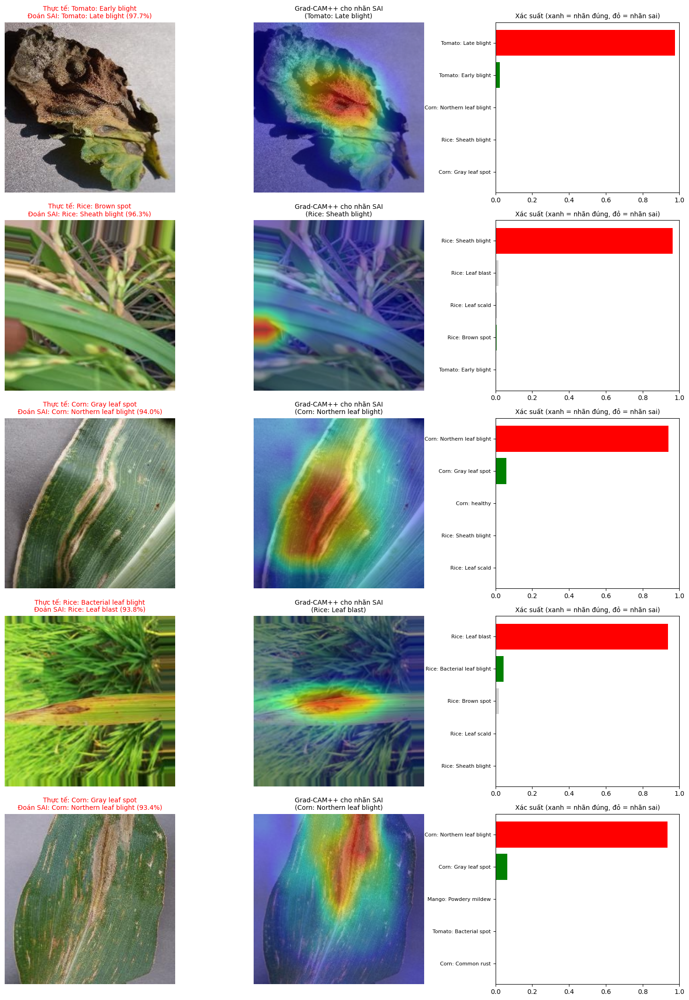

In [ ]:
# ============ CELL 16: PHÂN TÍCH LỖI (SAI + CONFIDENCE CAO NHẤT) ============
wrong = np.where(y_true != y_pred)[0]
print(f"Số ảnh dự đoán sai trên tập Test: {len(wrong)} / {len(y_true)}")

if len(wrong) == 0:
    print("Mô hình đúng 100% trên tập Test — không có ca sai để phân tích.")
else:
    same_crop = np.array([class_crops[t] == class_crops[p] for t, p in zip(y_true[wrong], y_pred[wrong])])
    print(f"  - Nhầm bệnh trong CÙNG một cây: {int(same_crop.sum())}")
    print(f"  - Nhầm sang cây KHÁC          : {int((~same_crop).sum())}")

    conf_wrong = y_prob[wrong, y_pred[wrong]]
    order = wrong[np.argsort(-conf_wrong)]          # sai nhưng "tự tin" nhất lên đầu

    df_wrong = pd.DataFrame({
        'file': [os.path.basename(test_files[i]) for i in order],
        'true': [short_names[y_true[i]] for i in order],
        'pred': [short_names[y_pred[i]] for i in order],
        'same_crop': [class_crops[y_true[i]] == class_crops[y_pred[i]] for i in order],
        'confidence': [round(float(y_prob[i, y_pred[i]]), 4) for i in order]})
    df_wrong.to_csv(f'{DRIVE_DIR}/misclassified_list.csv', index=False)
    print(df_wrong.head(10).to_string(index=False))

    top_k = min(5, len(order))
    fig, axes = plt.subplots(top_k, 3, figsize=(15, 4.3 * top_k))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(order[:top_k]):
        t, p = int(y_true[i]), int(y_pred[i])
        img_rgb = cv2.cvtColor(cv2.imread(test_files[i]), cv2.COLOR_BGR2RGB)
        img_224 = cv2.resize(img_rgb, (224, 224), interpolation=cv2.INTER_LINEAR)
        cam_p, _, _ = grad_cam_plus_plus(img_224, class_idx=p)

        axes[r, 0].imshow(img_rgb)
        axes[r, 0].set_title(f"Thực tế: {short_names[t]}\nĐoán SAI: {short_names[p]} ({y_prob[i, p]:.1%})",
                             color='red', fontsize=10)
        axes[r, 1].imshow(overlay_heatmap(img_224, cam_p))
        axes[r, 1].set_title(f"Grad-CAM++ cho nhãn SAI\n({short_names[p]})", fontsize=10)
        axes[r, 0].axis('off'); axes[r, 1].axis('off')

        ids = list(np.argsort(y_prob[i])[::-1][:5])
        if t not in ids:
            ids.append(t)
        cols = ['green' if k == t else ('red' if k == p else 'lightgray') for k in ids]
        axes[r, 2].barh([short_names[k] for k in ids], [y_prob[i, k] for k in ids], color=cols)
        axes[r, 2].set_xlim(0, 1)
        axes[r, 2].invert_yaxis()
        axes[r, 2].tick_params(axis='y', labelsize=8)
        axes[r, 2].set_title("Xác suất (xanh = nhãn đúng, đỏ = nhãn sai)", fontsize=10)
    plt.tight_layout()
    plt.savefig(f'{DRIVE_DIR}/top_misclassified_analysis.png', dpi=200, bbox_inches='tight')
    plt.show()

Saving images (1).jpg to images (1).jpg

                     KẾT QUẢ PHÂN TÍCH                      


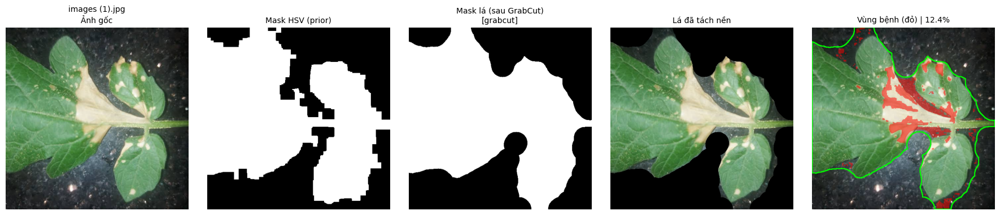

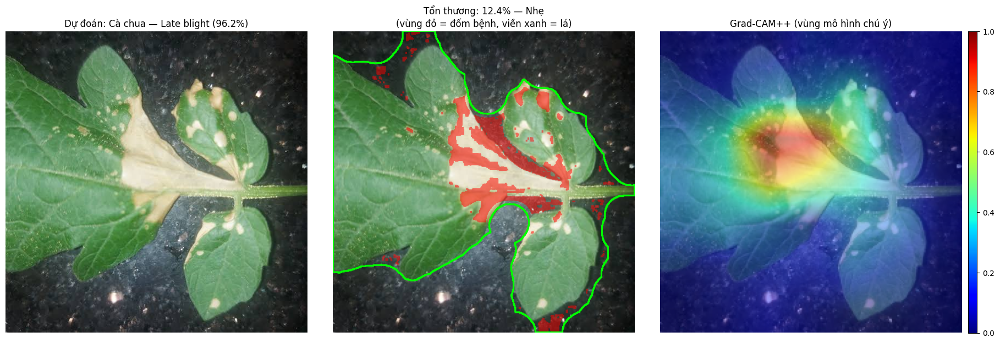


📄 File         : images (1).jpg
🔍 Chẩn đoán    : ⚠️  CÓ BỆNH
🌱 Cây dự đoán  : Cà chua (Tomato) — xác suất cây: 96.7%
🏷️  Bệnh/tình trạng: Bệnh mốc sương (sương mai) (Late blight) — độ tin cậy lớp: 96.2%
🌿 % Tổn thương : 12.4%
🩺 Mức độ       : Nhẹ
🔬 Phân đoạn    : grabcut

   Top-3 dự đoán:
   1. Cà chua — Bệnh mốc sương (sương mai) (Late blight)
       96.2%  ████████████████████████████
   2. Bắp — Bệnh đốm lá lớn (cháy lá Northern) (Northern leaf blight)
        1.5%  
   3. Lúa — Bệnh khô vằn (Sheath blight)
        0.7%  

   ⚠️ Lưu ý: mô hình chỉ biết 5 loại cây đã huấn luyện và học trên ảnh từ các bộ dữ liệu có sẵn;
      ảnh ngoài đồng có thể kém chính xác, % tổn thương chỉ là ước lượng theo màu.
      Hãy tham khảo cán bộ bảo vệ thực vật / khuyến nông địa phương trước khi xử lý.
────────────────────────────────────────────────────────────

📁 Đã lưu: /content/drive/MyDrive/plant_disease_results_5crops/upload_summary.csv
          file   crop crop_vi  crop_prob     disease      

In [ ]:
# ============ CELL 17 (TÙY CHỌN): SUY LUẬN TRÊN ẢNH CỦA BẠN / ẢNH CHỤP NGOÀI ĐỒNG ============
# Đặt True rồi chạy cell để upload 1-3 ảnh lá (nên có ảnh nền đất/cỏ để minh họa "nền phức tạp").
# Lưu ý: mô hình học trên ảnh từ các bộ dữ liệu có sẵn nên NHÃN DỰ ĐOÁN trên ảnh ngoài đồng kém tin cậy;
# phần phân đoạn lá và % tổn thương vẫn chạy độc lập với mô hình nhưng cũng có thể sai khi nền giống màu lá.
RUN_UPLOAD_DEMO = True
LOW_CONF = 0.70          # dưới ngưỡng này (độ tin cậy lớp hoặc cây) thì báo "không chắc chắn"

# Tên bệnh tiếng Việt (khóa = phần sau "___" của tên lớp). Một số tên gọi khác nhau theo vùng/tài liệu,
# hãy đối chiếu lại với tài liệu bảo vệ thực vật khi viết báo cáo.
DISEASE_VI = {
    'healthy':              'Lá khỏe mạnh',
    # Cà chua / ớt
    'Early_blight':         'Bệnh đốm vòng (đốm sớm)',
    'Late_blight':          'Bệnh mốc sương (sương mai)',
    'Leaf_Mold':            'Bệnh mốc lá',
    'Bacterial_spot':       'Bệnh đốm vi khuẩn',
    'Anthracnose':          'Bệnh thán thư',
    'Cercospora_leaf_spot': 'Bệnh đốm lá Cercospora',
    'Leaf_curl':            'Bệnh xoăn lá',
    'Powdery_mildew':       'Bệnh phấn trắng',
    'Nutrient_deficiency':  'Thiếu dinh dưỡng',
    'Whitefly':             'Tổn thương do rầy phấn trắng',
    # Bắp
    'Gray_leaf_spot':       'Bệnh đốm xám lá',
    'Common_rust':          'Bệnh gỉ sắt thông thường',
    'Northern_leaf_blight': 'Bệnh đốm lá lớn (cháy lá Northern)',
    # Lúa
    'Bacterial_leaf_blight':'Bệnh cháy bìa lá (bạc lá) do vi khuẩn',
    'Brown_spot':           'Bệnh đốm nâu',
    'Leaf_blast':           'Bệnh đạo ôn lá',
    'Leaf_scald':           'Bệnh cháy lá (leaf scald)',
    'Sheath_blight':        'Bệnh khô vằn',
    'Tungro':               'Bệnh Tungro (vàng lá do virus)',
    # Xoài
    'Bacterial_canker':     'Bệnh loét vi khuẩn',
    'Cutting_weevil':       'Tổn thương do bọ vòi voi cắt lá',
    'Die_back':             'Bệnh khô cành (chết ngược)',
    'Gall_midge':           'Tổn thương do muỗi gây u lá',
    'Sooty_mould':          'Bệnh nấm bồ hóng',
}


def disease_bilingual(class_idx):
    # Trả về: "Tên tiếng Việt (English name)" của lớp bệnh
    dis = disease_of_name(class_names[class_idx])
    en = dis.replace('_', ' ')
    vi = DISEASE_VI.get(dis, en)          # nếu thiếu trong bảng thì dùng tên tiếng Anh
    return f"{vi} ({en})"


def label_bilingual(short_label):
    # short_label dạng "Rice: Leaf blast" -> "Lúa — Bệnh đạo ôn lá (Leaf blast)"
    idx = short_names.index(short_label)
    return f"{CROP_VI[class_crops[idx]]} — {disease_bilingual(idx)}"


if RUN_UPLOAD_DEMO:
    up = files.upload()
    if not up:
        print("⚠️ Chưa chọn file nào.")
    else:
        print(f"\n{'=' * 60}\n{'KẾT QUẢ PHÂN TÍCH':^60}\n{'=' * 60}")
        all_results = []
        for name, data in up.items():
            img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                print(f"❌ Không đọc được ảnh: {name}")
                continue
            stem = re.sub(r'[^A-Za-z0-9_-]', '_', os.path.splitext(name)[0])

            cv_steps_figure([(name, img)], save_name=f'upload_{stem}_cv_steps.png')
            r = predict_pipeline(img, tag=f'upload_{stem}')

            pred_idx = short_names.index(r['top3'][0][0])        # chỉ số lớp được dự đoán
            disease_text = disease_bilingual(pred_idx)

            if r['conf'] < LOW_CONF or r['crop_prob'] < LOW_CONF:
                verdict = '❓ KHÔNG CHẮC CHẮN (độ tin cậy thấp), cần kiểm tra thêm'
            else:
                verdict = '✅ KHỎE MẠNH' if r['is_healthy'] else '⚠️  CÓ BỆNH'

            print(f"\n📄 File         : {name}")
            print(f"🔍 Chẩn đoán    : {verdict}")
            print(f"🌱 Cây dự đoán  : {CROP_VI[r['crop']]} ({r['crop']}) — xác suất cây: {r['crop_prob']:.1%}")
            print(f"🏷️  Bệnh/tình trạng: {disease_text} — độ tin cậy lớp: {r['conf']:.1%}")
            print(f"🌿 % Tổn thương : {fmt_sev(r['sev'])}")
            print(f"🩺 Mức độ       : {r['grade']}")
            print(f"🔬 Phân đoạn    : {r['method']}")
            print("\n   Top-3 dự đoán:")
            for rank, (lbl, prob) in enumerate(r['top3'], 1):
                print(f"   {rank}. {label_bilingual(lbl)}")
                print(f"      {prob:6.1%}  {'█' * int(prob * 30)}")
            print("\n   ⚠️ Lưu ý: mô hình chỉ biết 5 loại cây đã huấn luyện và học trên ảnh từ các bộ dữ liệu có sẵn;")
            print("      ảnh ngoài đồng có thể kém chính xác, % tổn thương chỉ là ước lượng theo màu.")
            print("      Hãy tham khảo cán bộ bảo vệ thực vật / khuyến nông địa phương trước khi xử lý.")
            print('─' * 60)

            all_results.append({
                'file': name, 'crop': r['crop'], 'crop_vi': CROP_VI[r['crop']], 'crop_prob': round(r['crop_prob'], 4),
                'disease': r['disease'], 'disease_vi': DISEASE_VI.get(disease_of_name(class_names[pred_idx]), r['disease']),
                'confidence': round(r['conf'], 4),
                'severity_%': round(r['sev'], 2) if not np.isnan(r['sev']) else None,
                'grade': r['grade'], 'seg_method': r['method'],
                'top2': label_bilingual(r['top3'][1][0]), 'top2_conf': round(r['top3'][1][1], 4),
                'top3': label_bilingual(r['top3'][2][0]), 'top3_conf': round(r['top3'][2][1], 4)})

        if all_results:
            df_upload = pd.DataFrame(all_results)
            df_upload.to_csv(f'{DRIVE_DIR}/upload_summary.csv', index=False, encoding='utf-8-sig')
            print(f"\n📁 Đã lưu: {DRIVE_DIR}/upload_summary.csv")
            print(df_upload.to_string(index=False))
else:
    print("Bỏ qua (RUN_UPLOAD_DEMO = False).")

In [ ]:
# ============ CELL 18: ĐÓNG GÓI TẬP TEST LÊN DRIVE (để nộp bài) ============
# /content/split chỉ tồn tại tạm thời, mất khi Colab ngắt kết nối -> nén tập test lưu lên Drive.
test_zip = shutil.make_archive(f'{DRIVE_DIR}/test_data', 'zip', SPLIT_ROOT, 'test')
print("Đã tạo:", test_zip, "|", round(os.path.getsize(test_zip) / 1e6, 1), "MB")

Đã tạo: /content/drive/MyDrive/plant_disease_results_5crops/test_data.zip | 46.3 MB


In [ ]:
# ============ CELL 19: DANH SÁCH FILE ĐÃ XUẤT RA DRIVE ============
for f in sorted(os.listdir(DRIVE_DIR)):
    print(f"{os.path.getsize(os.path.join(DRIVE_DIR, f)) / 1024:9.1f} KB  {f}")

  37737.4 KB  best_model.keras
      0.5 KB  class_names.csv
      1.8 KB  classification_report.csv
    310.3 KB  confusion_matrix.png
    101.8 KB  confusion_matrix_crop.png
   3307.1 KB  cv_steps.png
      1.5 KB  data_found.csv
      1.0 KB  data_split.csv
    455.2 KB  demo_Corn__Common_rust.png
    372.1 KB  demo_Corn__healthy.png
    270.1 KB  demo_Mango__Anthracnose.png
    279.4 KB  demo_Mango__healthy.png
    508.7 KB  demo_Pepper__Bacterial_spot.png
    498.2 KB  demo_Pepper__healthy.png
    415.4 KB  demo_Rice__Bacterial_leaf_blight.png
    361.3 KB  demo_Rice__healthy.png
    468.7 KB  demo_Tomato__Bacterial_spot.png
    559.3 KB  demo_Tomato__healthy.png
      1.2 KB  demo_summary.csv
   1952.8 KB  demo_upload_images.png
   2548.1 KB  demo_upload_images__1_.png
    493.7 KB  demo_upload_images__2_.png
   1446.5 KB  demo_upload_images__3_.png
   1446.5 KB  demo_upload_images__3___1_.png
    143.4 KB  history_loss_acc.png
      5.5 KB  misclassified_list.csv
      0.3 KB  p

## Ghi chú cho báo cáo

**Dữ liệu**
- Cà chua, bắp, ớt chuông: PlantVillage (ảnh lá chụp trong phòng thí nghiệm, nền đồng nhất). Lúa: Rice Disease Dataset (Kaggle, anshulm257). Xoài: MangoLeafBD (Kaggle, aryashah2k). Ớt cay (nếu dùng): bộ ảnh tải thủ công từ Mendeley Data. Hãy ghi rõ nguồn và giấy phép của từng bộ dữ liệu trong báo cáo.
- Mỗi lớp lấy tối đa 500 ảnh (ngẫu nhiên, seed cố định), chia 70/15/15, ảnh thu nhỏ cạnh dài ≤ 512 px. Nhãn có dạng `Cây___Bệnh`, mô hình dự đoán đồng thời cây và bệnh.
- Nhóm "Ớt" mặc định chỉ có **ớt chuông** (Bacterial spot, healthy) từ PlantVillage, không phải ớt cay phổ biến ở Việt Nam. Một số lớp xoài (Cutting weevil, Gall midge) là tổn thương do côn trùng chứ không phải bệnh do nấm/vi khuẩn.

**Thiết kế**
- Mô hình nhận **ảnh gốc** 224×224; GrabCut/HSV chạy song song trên cùng ảnh để hiển thị lá đã tách nền và tính % tổn thương.
- Huấn luyện 2 pha: warm-up 4 epoch (đóng băng base model, lr = 1e-3), sau đó fine-tune 60 lớp cuối (lr = 3e-5, BatchNorm đóng băng, tối đa 20 epoch với EarlyStopping + ReduceLROnPlateau), batch size 64, class weights cân bằng.
- Grad-CAM++ tính trên **logit trước softmax**, dùng công thức dạng đóng (α = g² / (2g² + ΣA·g³)).
- % tổn thương = (số pixel không "khỏe" trong lõi lá) / (số pixel lõi lá) × 100. Mức độ (Rất nhẹ/Nhẹ/Trung bình/Nặng) dùng ngưỡng tham khảo, không phải chuẩn nông học.
- Ngưỡng HSV được kiểm chứng theo từng cây trên tập **val** (Cell 8); tập test chỉ dùng để báo cáo kết quả cuối.

**Hạn chế nên nêu**
- **Thiên lệch nguồn dữ liệu:** mỗi cây đến từ một bộ dữ liệu khác nhau (nền, camera, ánh sáng khác nhau), nên mô hình có thể nhận ra "bộ dữ liệu" thay vì đặc điểm lá; độ chính xác nhận diện cây có thể cao hơn thực tế. Ảnh chụp ngoài đồng thường cho kết quả thấp hơn.
- **Ảnh gần giống nhau giữa các tập:** PlantVillage có nhiều ảnh của cùng một chiếc lá ở các góc xoay khác nhau, và một số bộ dữ liệu có ảnh đã được augmentation sẵn; chia ngẫu nhiên có thể để ảnh gần giống nhau rơi vào cả train và test, làm accuracy cao hơn thực tế.
- PlantVillage và các bộ trên **không có mask đốm bệnh** nên không có ground truth để đo sai số của % tổn thương; đây là ước lượng theo màu. Bảng và biểu đồ ở Cell 8 là minh chứng định tính.
- Ngưỡng HSV được chỉnh ban đầu cho lá cà chua; với lá lúa (thon dài), lá xoài, lá bắp có thể cần chỉnh riêng. Bóng đổ, tổn thương xám/đen ít bão hòa, đốm li ti nhạt màu hoặc gân lá sáng có thể bị tính sai. Nền cỏ xanh cùng dải màu với lá nên prior HSV coi cả cỏ là lá.
- Grad-CAM++ đôi khi tập trung vào vùng không phải tổn thương (ví dụ cuống lá), và với các cặp nhãn hay nhầm heatmap của nhãn sai và nhãn đúng có thể gần như trùng nhau.
- Kết quả không tái lập tuyệt đối từng bit trên GPU dù đã cố định seed.